In [2]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np


class Read:
    def __init__(self, filepathg,filepathn,numb):
        file3=uproot.open(filepathg)
        file2=uproot.open(filepathn)
        self.mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
        self.targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
        self.Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
        self.Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
        self.truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
        self.Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
        self.q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
        self.q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
        self.W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
        self.Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
        self.Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
        self.weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
        self.px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
        self.py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
        self.pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
        self.E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
        self.pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
        self.chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
        self.parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
        self.isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
        self.angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
        self.nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
        self.nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
        self.flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate
        self.incident_counter_w_med=file3['Events;1']['incident'].array()+numb
        self.px_gibuu_w_med=file3['Events;1']['momX'].array()
        self.py_gibuu_w_med=file3['Events;1']['momY'].array()
        self.pz_gibuu_w_med=file3['Events;1']['momZ'].array()
        self.E_gibuu_w_med=file3['Events;1']['momE'].array()
        self.ID_gibuu_w_med=file3['Events;1']['ID'].array()
        self.charge_gibuu_w_med=file3['Events;1']['Charge'].array()
        self.history_gibuu_w_med=file3['Events;1']['history'].array()
        self.prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()


workdir="/gpfs/group/t2k/beam/work/pingaldg/backup_release3/release/output_wpotential_wcoll_offshell_ccqe_plus_res_ehouarn/"
read=Read(workdir+"workdir2/root_files/jg_inclusive.root",workdir+"workdir2/root_files/NIWG_ehouarn_inclusive.root",0)
read1=Read(workdir+"workdir3/root_files/jg_inclusive2.root",workdir+"workdir3/root_files/NIWG_ehouarn_inclusive2.root",1500000)
read2=Read(workdir+"workdir4/root_files/jg_inclusive3.root",workdir+"workdir4/root_files/NIWG_ehouarn_inclusive3.root",3000000)
read3=Read(workdir+"workdir5/root_files/jg_inclusive4.root",workdir+"workdir5/root_files/NIWG_ehouarn_inclusive4.root",4500000)
read4=Read(workdir+"workdir/root_files/jg_inclusive5.root",workdir+"workdir/root_files/NIWG_ehouarn_inclusive5.root",6000000)


In [3]:
mode=ak.concatenate([read.mode,read1.mode,read2.mode,read3.mode,read4.mode])
Nprimary=ak.concatenate([read.Nprimary,read1.Nprimary,read2.Nprimary,read3.Nprimary,read4.Nprimary]) ## number of particles in primary interaction
Nupdg=ak.concatenate([read.Nupdg,read1.Nupdg,read2.Nupdg,read3.Nupdg,read4.Nupdg]) ##  numu beam
targetA=ak.concatenate([read.targetA,read1.targetA,read2.targetA,read3.targetA,read4.targetA])## C in our case
truenuE=ak.concatenate([read.truenuE,read1.truenuE,read2.truenuE,read3.truenuE,read4.truenuE]) ## fixed energy beam
Q2=ak.concatenate([read.Q2,read1.Q2,read2.Q2,read3.Q2,read4.Q2]) ## Q2
q3=ak.concatenate([read.q3,read1.q3,read2.q3,read3.q3,read4.q3]) ## q3
q0=ak.concatenate([read.q0,read1.q0,read2.q0,read3.q0,read4.q0]) ## q0
W=ak.concatenate([read.W,read1.W,read2.W,read3.W,read4.W]) ## W
Emiss=ak.concatenate([read.Emiss,read1.Emiss,read2.Emiss,read3.Emiss,read4.Emiss]) ## missing energy E
Pmiss=ak.concatenate([read.Pmiss,read1.Pmiss,read2.Pmiss,read3.Pmiss,read4.Pmiss]) ## missing momentum p
weight=ak.concatenate([read.weight,read1.weight,read2.weight,read3.weight,read4.weight]) ## weight
px=ak.concatenate([read.px,read1.px,read2.px,read3.px,read4.px])
py=ak.concatenate([read.py,read1.py,read2.py,read3.py,read4.py])
pz=ak.concatenate([read.pz,read1.pz,read2.pz,read3.pz,read4.pz])
E=ak.concatenate([read.E,read1.E,read2.E,read3.E,read4.E])
pdg=ak.concatenate([read.pdg,read1.pdg,read2.pdg,read3.pdg,read4.pdg])
chase=ak.concatenate([read.chase,read1.chase,read2.chase,read3.chase,read4.chase]) ## whther the particle is alive or not
parent=ak.concatenate([read.parent,read1.parent,read2.parent,read3.parent,read4.parent]) ## parent
isatPV=ak.concatenate([read.isatPV,read1.isatPV,read2.isatPV,read3.isatPV,read4.isatPV]) ## parent
angle=ak.concatenate([read.angle,read1.angle,read2.angle,read3.angle,read4.angle])
nuindex=ak.concatenate([read.nuindex,read1.nuindex,read2.nuindex,read3.nuindex,read4.nuindex])
nucindex=ak.concatenate([read.nucindex,read1.nucindex,read2.nucindex,read3.nucindex,read4.nucindex])
flesp_index=ak.concatenate([read.flesp_index,read1.flesp_index,read2.flesp_index,read3.flesp_index,read4.flesp_index]) ## Some useful particle stack indicies to pre-calculate
incident_counter_w_med=ak.concatenate([read.incident_counter_w_med,read1.incident_counter_w_med,read2.incident_counter_w_med,read3.incident_counter_w_med,read4.incident_counter_w_med])
px_gibuu_w_med=ak.concatenate([read.px_gibuu_w_med,read1.px_gibuu_w_med,read2.px_gibuu_w_med,read3.px_gibuu_w_med,read4.px_gibuu_w_med])
py_gibuu_w_med=ak.concatenate([read.py_gibuu_w_med,read1.py_gibuu_w_med,read2.py_gibuu_w_med,read3.py_gibuu_w_med,read4.py_gibuu_w_med])
pz_gibuu_w_med=ak.concatenate([read.pz_gibuu_w_med,read1.pz_gibuu_w_med,read2.pz_gibuu_w_med,read3.pz_gibuu_w_med,read4.pz_gibuu_w_med])
E_gibuu_w_med=ak.concatenate([read.E_gibuu_w_med,read1.E_gibuu_w_med,read2.E_gibuu_w_med,read3.E_gibuu_w_med,read4.E_gibuu_w_med])
ID_gibuu_w_med=ak.concatenate([read.ID_gibuu_w_med,read1.ID_gibuu_w_med,read2.ID_gibuu_w_med,read3.ID_gibuu_w_med,read4.ID_gibuu_w_med])
charge_gibuu_w_med=ak.concatenate([read.charge_gibuu_w_med,read1.charge_gibuu_w_med,read2.charge_gibuu_w_med,read3.charge_gibuu_w_med,read4.charge_gibuu_w_med])
history_gibuu_w_med=ak.concatenate([read.history_gibuu_w_med,read1.history_gibuu_w_med,read2.history_gibuu_w_med,read3.history_gibuu_w_med,read4.history_gibuu_w_med])
prodid_gibuu_w_med=ak.concatenate([read.prodid_gibuu_w_med,read1.prodid_gibuu_w_med,read2.prodid_gibuu_w_med,read3.prodid_gibuu_w_med,read4.prodid_gibuu_w_med])
len(mode)

7500000

In [4]:
np.unique(ak.flatten(history_gibuu_w_med))

<Array [-14000003, -13000003, ..., 14002001, 15000002] type='555 * int64'>

In [116]:
px

<Array [[0, -0.0703, ..., -0.22, 0.21], ...] type='7500000 * var * float64'>

In [125]:
row_idx = ak.local_index(px, axis=0)

out = px[row_idx, flesp_index]
out

<Array [-0.277, 0.113, 0.0104, ..., -0.299, -0.0686] type='7500000 * float64'>

In [5]:
idx=np.arange(0,7500000,1)
mask_chase=ak.sum(chase, axis=1)>0
idx=idx[mask_chase]
print(idx,len(idx))

[      0       1       2 ... 7499997 7499998 7499999] 7436174


In [6]:
idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
# idx=incident_counter_gibuu_wo_med1[idx]
idx2=incident_counter_w_med[idx2]

# _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
_, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)

pdgf=ak.flatten(pdg[idx1])
chasef=ak.flatten(chase[idx1])
Ef=ak.flatten(E[idx1])
Pxf=ak.flatten(px[idx1])
Pyf=ak.flatten(py[idx1])
Pzf=ak.flatten(pz[idx1])
Ptf=np.sqrt(Pxf**2+Pyf**2)
Costhetaf=Pzf/np.sqrt(Pxf**2+Pyf**2+Pzf**2)
modef=ak.flatten(mode[idx1]*ak.ones_like(pdg[idx1]))
enf=ak.flatten(truenuE[idx1]*ak.ones_like(pdg[idx1]))
# ################################
pdgf_gibuu_w_med=ak.flatten(ID_gibuu_w_med[idx2][:,2:])
chargef_gibuu_w_med=ak.flatten(charge_gibuu_w_med[idx2][:,2:])
historyf_gibuu_w_med=ak.flatten(history_gibuu_w_med[idx2][:,2:])
pxf_gibuu_w_med=ak.flatten(px_gibuu_w_med[idx2][:,2:])
pyf_gibuu_w_med=ak.flatten(py_gibuu_w_med[idx2][:,2:])
pzf_gibuu_w_med=ak.flatten(pz_gibuu_w_med[idx2][:,2:])
ptf_gibuu_w_med=np.sqrt(pxf_gibuu_w_med**2+pyf_gibuu_w_med**2)
modef_gibuu=ak.flatten(mode[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
enf_gibuu=ak.flatten(truenuE[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
Ef_gibuu_w_med=ak.flatten(E_gibuu_w_med[idx2][:,2:])
costheta_w_med=pzf_gibuu_w_med/np.sqrt(pxf_gibuu_w_med*pxf_gibuu_w_med+pyf_gibuu_w_med*pyf_gibuu_w_med+pzf_gibuu_w_med*pzf_gibuu_w_med)
costheta_w_med[costheta_w_med<=np.cos(np.pi)]

<Array [] type='0 * float64'>

/home/t2k/pingaldg/.local/lib/python3.9/site-packages/awkward/_nplikes/array_module.py:251: RuntimeWarning: invalid value encountered in sqrt
  return impl(*broadcasted_args, **(kwargs or {}))


(100, 1000000)

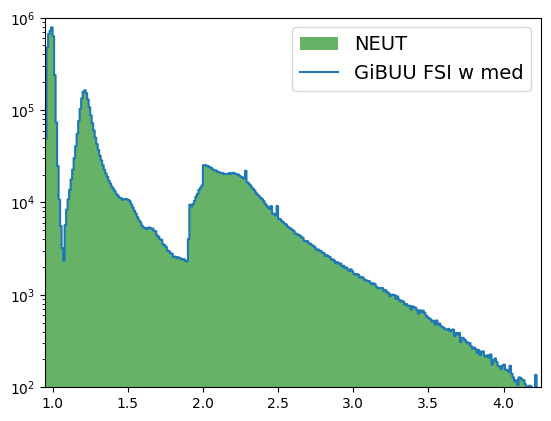

In [5]:
boson_x=0.0-px_gibuu_w_med[idx2][:,0]
boson_y=0.0-py_gibuu_w_med[idx2][:,0]
boson_z=truenuE[idx1]-pz_gibuu_w_med[idx2][:,0]
boson_E=truenuE[idx1]-E_gibuu_w_med[idx2][:,0]


nuc_x=px_gibuu_w_med[idx2][:,1]
nuc_y=py_gibuu_w_med[idx2][:,1]
nuc_z=pz_gibuu_w_med[idx2][:,1]
nuc_E=E_gibuu_w_med[idx2][:,1]


nuc_x1=px_gibuu_w_med[idx2][:,1]+px[idx1][:,2]
nuc_y1=py_gibuu_w_med[idx2][:,1]+py[idx1][:,2]
nuc_z1=pz_gibuu_w_med[idx2][:,1]+pz[idx1][:,2]
nuc_E1=E_gibuu_w_med[idx2][:,1]+E[idx1][:,2]

wx=boson_x+nuc_x
wy=boson_y+nuc_y
wz=boson_z+nuc_z
wE=boson_E+nuc_E

wx1=boson_x+nuc_x1
wy1=boson_y+nuc_y1
wz1=boson_z+nuc_z1
wE1=boson_E+nuc_E1

w_gibuu_w_med= np.sqrt(wE*wE-wx*wx-wy*wy-wz*wz)
w_gibuu_w_med1= np.sqrt(wE1*wE1-wx1*wx1-wy1*wy1-wz1*wz1)

bins_array=np.arange(0.95,10,0.01)
plt.hist(W[idx1],bins=bins_array,color="green",alpha=.60,histtype='bar', label="NEUT")
hist,_=np.histogram(np.array(w_gibuu_w_med[mode[idx1]!=2]),bins=bins_array)
hist1,_=np.histogram(np.array(w_gibuu_w_med1[mode[idx1]==2]),bins=bins_array)
plt.step(_[:-1],hist+hist1, where="post",label="GiBUU FSI w med")

plt.legend(fontsize=14)
plt.yscale("log")
len(w_gibuu_w_med),len(W[idx1])
plt.xlim(0.95,4.25)
plt.ylim(100,10**6)
# len(w_gibuu_wo_med),

In [6]:
import pandas as pd
import numpy as np
from scipy.interpolate import make_interp_spline
file=pd.read_csv("Pion_xsec.dat")

def read():
    z=[]
    for lines in file["# 1pi :Graczyk & Sobczyk default :MA=0.95"]:
        x=lines.split()
        y=[int(x[0]),int(x[1]), float(x[2]),float(x[3]),float(x[4]),float(x[5])]
        z.append(y)
    return np.array(z)
read()

array([[ 1.40000e+01,  1.00000e+00,  1.50000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       [ 1.40000e+01,  1.00000e+00,  2.00000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       [ 1.40000e+01,  1.00000e+00,  2.50000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       ...,
       [ 1.40000e+01,  2.00000e+00,  6.00000e+02,  7.36338e+00,
         1.63726e+00,  8.19062e-01],
       [ 1.40000e+01,  2.00000e+00,  8.00000e+02,  7.36329e+00,
         1.63904e+00,  8.20760e-01],
       [ 1.40000e+01,  2.00000e+00,  1.00000e+03,  7.36326e+00,
         1.64071e+00,  8.22473e-01]])

Text(0, 0.5, 'Xsec_$\\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)')

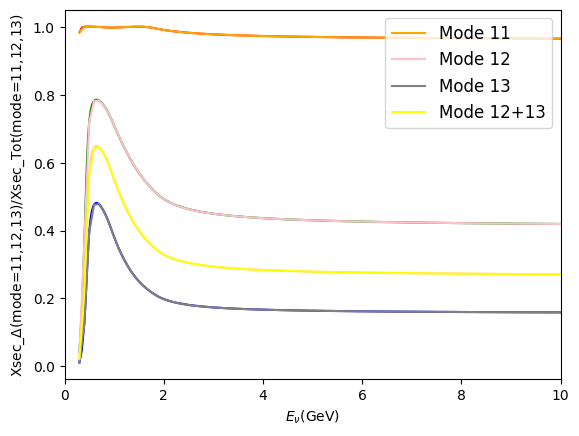

In [7]:
import matplotlib.pyplot as plt
results=np.array(read())
modex=results[:,1]
neutrinox=results[:,0]
enx=results[:,2]
mode11x=results[:,3]
mode12x=results[:,4]
mode13x=results[:,5]

tot11=mode11x[(modex==1)]
tot12=mode12x[(modex==1)]
tot13=mode13x[(modex==1)]

tot11delta=mode11x[(modex==2)]
tot12delta=mode12x[(modex==2)]
tot13delta=mode13x[(modex==2)]



enx=enx[modex==1]

plt.plot(enx[3:],tot11delta[3:]/tot11[3:], "red")
plt.plot(enx[3:],tot12delta[3:]/tot12[3:],"green")
plt.plot(enx[3:],tot13delta[3:]/tot13[3:], "blue")
plt.plot(enx[3:],(tot13delta[3:]+tot12delta[3:])/(tot12[3:]+tot13[3:]), color="pink")
bspl1 = make_interp_spline(enx[3:],tot11delta[3:]/tot11[3:])
bspl2 = make_interp_spline(enx[3:],tot12delta[3:]/tot12[3:])
bspl3 = make_interp_spline(enx[3:],tot13delta[3:]/tot13[3:])
bspl4 = make_interp_spline(enx[3:],(tot13delta[3:]+tot12delta[3:])/(tot12[3:]+tot13[3:]))

xx = np.linspace(0.3, 10, 100)

plt.plot(xx,bspl1(xx), "orange", label="Mode 11")
plt.plot(xx,bspl2(xx), "pink",label="Mode 12")
plt.plot(xx,bspl3(xx), "gray",label="Mode 13")
plt.plot(xx,bspl4(xx), "yellow",label="Mode 12+13")
plt.legend(fontsize=12)
enx[2:]
plt.xlim(0,10)
plt.xlabel(r"$E_{\nu}$(GeV)")
plt.ylabel(r"Xsec_$\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)")

## total Pion yield from all events

Text(0, 0.5, 'Counts')

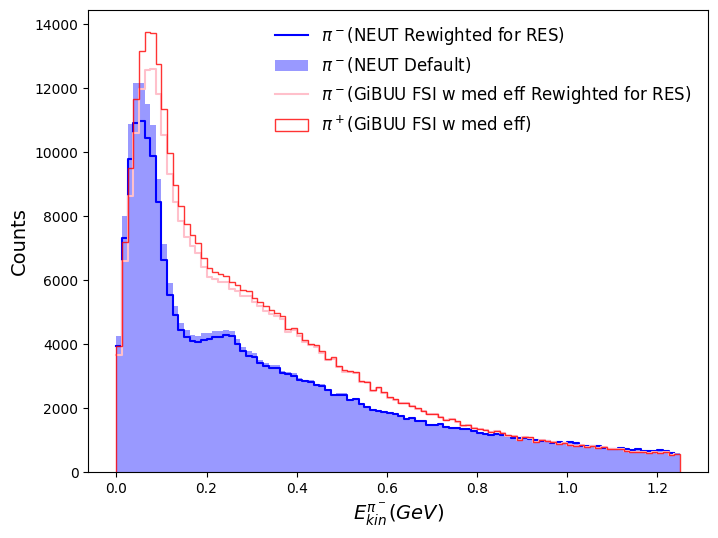

In [194]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot()
weight=np.zeros(len(Ef[np.logical_and.reduce((pdgf==-211,chasef==1))]))


hist1,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==-211,chasef==1,modef==11))]-0.13957,bins=100,weights=bspl1(enf[np.logical_and.reduce((pdgf==-211,chasef==1,modef==11))]),range=(0,1.25))
hist2,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==-211,chasef==1,modef==12))]-0.13957,bins=100,weights=bspl2(enf[np.logical_and.reduce((pdgf==-211,chasef==1,modef==12))]),range=(0,1.25))
hist3,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==-211,chasef==1,modef==13))]-0.13957,bins=100,weights=bspl3(enf[np.logical_and.reduce((pdgf==-211,chasef==1,modef==13))]), range=(0,1.25))


hist4,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==-211,chasef==1,modef==1))]-0.13957,bins=100,range=(0,1.25))
hist5,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==-211,chasef==1,modef==2))]-0.13957,bins=100,range=(0,1.25))
hist6,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==-211,chasef==1,modef==26))]-0.13957,bins=100, range=(0,1.25))

binc=(bin1[1:]+bin1[:-1])/2
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6,color="blue",  where="post",label=r"$\pi^-$(NEUT Rewighted for RES)")
# ax.hist(Ef[np.logical_and.reduce((pdgf==211,chasef==1))]-0.13957,bins=100,weight=, color="red", alpha=0.4, label=r"$\pi^+$(NEUT Default)",range=(0,1.25))
# costheta_cutpi_neut=Costhetaf[np.logical_and.reduce((pdgf==111,chasef==1))]
ax.hist(Ef[np.logical_and.reduce((pdgf==-211,chasef==1))]-0.13957,bins=100,color="blue",alpha=0.4, label=r"$\pi^-$(NEUT Default)",range=(0,1.25))


# eg_cutpi_wo_med=Ef_gibuu_wo_med[np.logical_and.reduce((pdgf_gibuu_wo_med==101,chargef_gibuu_wo_med==1))]-0.13957
# costheta_cutn_w_med=costheta_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==1,chargef_gibuu_w_med==0))]
###############################
###############################
eg_cutpi_w_med_mode11=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==11))]-0.13957
eg_cutpi_w_med_mode12=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==12))]-0.13957
eg_cutpi_w_med_mode13=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==13))]-0.13957
eg_cutpi_w_med_mode1=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==1))]-0.13957
eg_cutpi_w_med_mode2=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==2))]-0.13957
eg_cutpi_w_med_mode26=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==26))]-0.13957


hist1g,bin1=np.histogram(eg_cutpi_w_med_mode11,bins=100,weights=bspl1(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==11))]),range=(0,1.25))
hist2g,bin1=np.histogram(eg_cutpi_w_med_mode12,bins=100,weights=bspl4(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==12))]),range=(0,1.25))
hist3g,bin1=np.histogram(eg_cutpi_w_med_mode13,bins=100,weights=bspl4(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1,modef_gibuu==13))]), range=(0,1.25))

hist4g,bin1=np.histogram(eg_cutpi_w_med_mode1,bins=100,range=(0,1.25))
hist5g,bin1=np.histogram(eg_cutpi_w_med_mode2,bins=100,range=(0,1.25))
hist6g,bin1=np.histogram(eg_cutpi_w_med_mode26,bins=100, range=(0,1.25))


plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g,color="pink",  where="post",label=r"$\pi^-$(GiBUU FSI w med eff Rewighted for RES) ")

binc=(bin1[1:]+bin1[:-1])/2

eg_cutpi_w_med=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==-1))]-0.13957
# costheta_cutn_w_med=costheta_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==1,chargef_gibuu_w_med==0))]
###############################
# ax.hist(eg_cutp[np.logicalaa_and.reduce((eg_cutp>0.00,costheta_cutp>=np.cos(np.pi)))],bins=100,color="red",alpha=0.4,histtype='step',label="p(GiBUU FSI)")
# ax.hist(eg_cutn[np.logical_and.reduce((eg_cutn>0.00,costheta_cutn>=np.cos(np.pi)))],bins=100,color="blue",alpha=0.4,histtype='step', label="n(GiBUU FSI)")
ax.hist(eg_cutpi_w_med[eg_cutpi_w_med>0.00],bins=100,color="red",alpha=0.8,histtype='step',label=r"$\pi^+$(GiBUU FSI w med eff)",range=(0,1.25))
# ax.hist(eg_cutpi_wo_med[eg_cutpi_wo_med>0.00],bins=100,color="blue",alpha=0.8,histtype='step',label=r"$\pi^+$(GiBUU FSI w/o med eff)",range=(0,0.5))

# ax.hist(eg_cutn_w_med[np.logical_and.reduce((eg_cutn_w_med>-100.00,costheta_cutn_w_med>=np.cos(np.pi)))],bins=100,color="brown",alpha=0.8,histtype='step', label="n(GiBUU FSI w med eff)",range=(0,0.5))
plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$E_{kin}^{\pi^-} (GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
# plt.savefig("jg_plots_300725/EkinH_gibuufsi_vs_neut.png")

Text(0, 0.5, 'Counts')

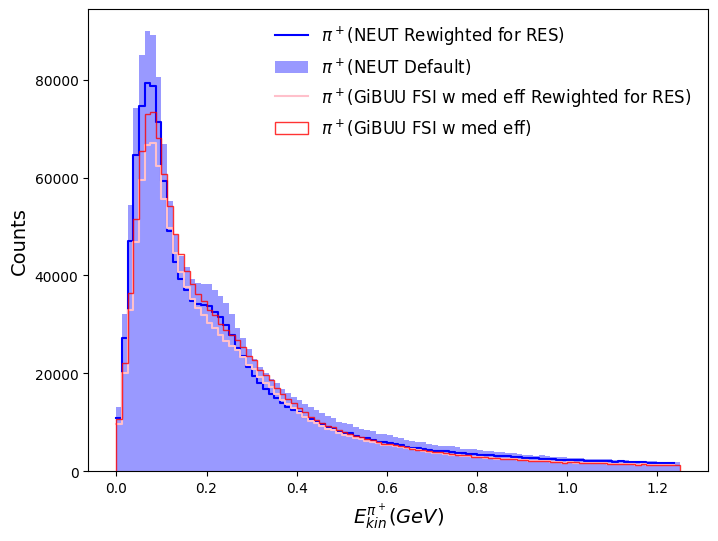

In [195]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot()
weight=np.zeros(len(Ef[np.logical_and.reduce((pdgf==211,chasef==1))]))


hist1,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==211,chasef==1,modef==11))]-0.13957,bins=100,weights=bspl1(enf[np.logical_and.reduce((pdgf==211,chasef==1,modef==11))]),range=(0,1.25))
hist2,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==211,chasef==1,modef==12))]-0.13957,bins=100,weights=bspl2(enf[np.logical_and.reduce((pdgf==211,chasef==1,modef==12))]),range=(0,1.25))
hist3,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==211,chasef==1,modef==13))]-0.13957,bins=100,weights=bspl3(enf[np.logical_and.reduce((pdgf==211,chasef==1,modef==13))]), range=(0,1.25))


hist4,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==211,chasef==1,modef==1))]-0.13957,bins=100,range=(0,1.25))
hist5,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==211,chasef==1,modef==2))]-0.13957,bins=100,range=(0,1.25))
hist6,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==211,chasef==1,modef==26))]-0.13957,bins=100, range=(0,1.25))

binc=(bin1[1:]+bin1[:-1])/2
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6,color="blue",  where="post",label=r"$\pi^+$(NEUT Rewighted for RES)")
# ax.hist(Ef[np.logical_and.reduce((pdgf==211,chasef==1))]-0.13957,bins=100,weight=, color="red", alpha=0.4, label=r"$\pi^+$(NEUT Default)",range=(0,1.25))
# costheta_cutpi_neut=Costhetaf[np.logical_and.reduce((pdgf==111,chasef==1))]
ax.hist(Ef[np.logical_and.reduce((pdgf==211,chasef==1))]-0.13957,bins=100,color="blue",alpha=0.4, label=r"$\pi^+$(NEUT Default)",range=(0,1.25))


# eg_cutpi_wo_med=Ef_gibuu_wo_med[np.logical_and.reduce((pdgf_gibuu_wo_med==101,chargef_gibuu_wo_med==1))]-0.13957
# costheta_cutn_w_med=costheta_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==1,chargef_gibuu_w_med==0))]
###############################
###############################
eg_cutpi_w_med_mode11=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==11))]-0.13957
eg_cutpi_w_med_mode12=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==12))]-0.13957
eg_cutpi_w_med_mode13=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==13))]-0.13957
eg_cutpi_w_med_mode1=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==1))]-0.13957
eg_cutpi_w_med_mode2=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==2))]-0.13957
eg_cutpi_w_med_mode26=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==26))]-0.13957


hist1g,bin1=np.histogram(eg_cutpi_w_med_mode11,bins=100,weights=bspl1(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==11))]),range=(0,1.25))
hist2g,bin1=np.histogram(eg_cutpi_w_med_mode12,bins=100,weights=bspl4(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==12))]),range=(0,1.25))
hist3g,bin1=np.histogram(eg_cutpi_w_med_mode13,bins=100,weights=bspl4(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1,modef_gibuu==13))]), range=(0,1.25))

hist4g,bin1=np.histogram(eg_cutpi_w_med_mode1,bins=100,range=(0,1.25))
hist5g,bin1=np.histogram(eg_cutpi_w_med_mode2,bins=100,range=(0,1.25))
hist6g,bin1=np.histogram(eg_cutpi_w_med_mode26,bins=100, range=(0,1.25))


plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g,color="pink",  where="post",label=r"$\pi^+$(GiBUU FSI w med eff Rewighted for RES) ")

binc=(bin1[1:]+bin1[:-1])/2

eg_cutpi_w_med=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==1))]-0.13957
# costheta_cutn_w_med=costheta_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==1,chargef_gibuu_w_med==0))]
###############################
# ax.hist(eg_cutp[np.logicalaa_and.reduce((eg_cutp>0.00,costheta_cutp>=np.cos(np.pi)))],bins=100,color="red",alpha=0.4,histtype='step',label="p(GiBUU FSI)")
# ax.hist(eg_cutn[np.logical_and.reduce((eg_cutn>0.00,costheta_cutn>=np.cos(np.pi)))],bins=100,color="blue",alpha=0.4,histtype='step', label="n(GiBUU FSI)")
ax.hist(eg_cutpi_w_med[eg_cutpi_w_med>0.00],bins=100,color="red",alpha=0.8,histtype='step',label=r"$\pi^+$(GiBUU FSI w med eff)",range=(0,1.25))
# ax.hist(eg_cutpi_wo_med[eg_cutpi_wo_med>0.00],bins=100,color="blue",alpha=0.8,histtype='step',label=r"$\pi^+$(GiBUU FSI w/o med eff)",range=(0,0.5))

# ax.hist(eg_cutn_w_med[np.logical_and.reduce((eg_cutn_w_med>-100.00,costheta_cutn_w_med>=np.cos(np.pi)))],bins=100,color="brown",alpha=0.8,histtype='step', label="n(GiBUU FSI w med eff)",range=(0,0.5))
plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$E_{kin}^{\pi^+} (GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
# plt.savefig("jg_plots_300725/EkinH_gibuufsi_vs_neut.png")

Text(0, 0.5, 'Counts')

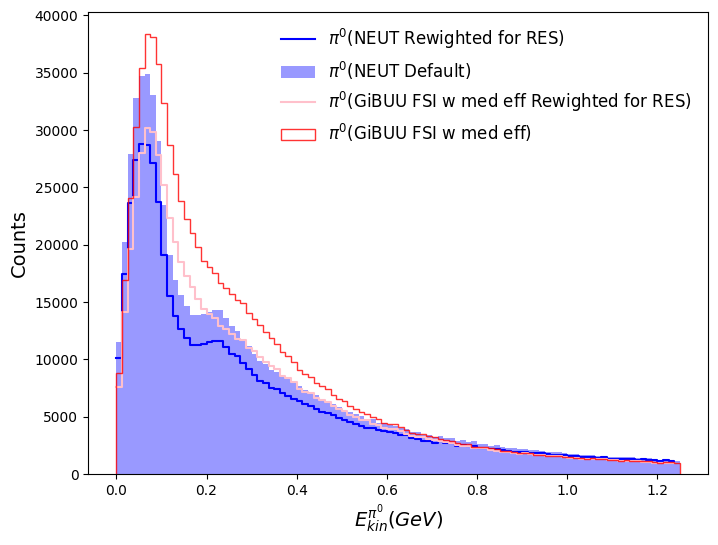

In [196]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot()
weight=np.zeros(len(Ef[np.logical_and.reduce((pdgf==111,chasef==1))]))


hist1,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==111,chasef==1,modef==11))]-0.13957,bins=100,weights=bspl1(enf[np.logical_and.reduce((pdgf==111,chasef==1,modef==11))]),range=(0,1.25))
hist2,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==111,chasef==1,modef==12))]-0.13957,bins=100,weights=bspl2(enf[np.logical_and.reduce((pdgf==111,chasef==1,modef==12))]),range=(0,1.25))
hist3,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==111,chasef==1,modef==13))]-0.13957,bins=100,weights=bspl3(enf[np.logical_and.reduce((pdgf==111,chasef==1,modef==13))]), range=(0,1.25))


hist4,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==111,chasef==1,modef==1))]-0.13957,bins=100,range=(0,1.25))
hist5,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==111,chasef==1,modef==2))]-0.13957,bins=100,range=(0,1.25))
hist6,bin1=np.histogram(Ef[np.logical_and.reduce((pdgf==111,chasef==1,modef==26))]-0.13957,bins=100, range=(0,1.25))

binc=(bin1[1:]+bin1[:-1])/2
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6,color="blue",  where="post",label=r"$\pi^0$(NEUT Rewighted for RES)")
# ax.hist(Ef[np.logical_and.reduce((pdgf==211,chasef==1))]-0.13957,bins=100,weight=, color="red", alpha=0.4, label=r"$\pi^+$(NEUT Default)",range=(0,1.25))
# costheta_cutpi_neut=Costhetaf[np.logical_and.reduce((pdgf==111,chasef==1))]
ax.hist(Ef[np.logical_and.reduce((pdgf==111,chasef==1))]-0.13957,bins=100,color="blue",alpha=0.4, label=r"$\pi^0$(NEUT Default)",range=(0,1.25))


# eg_cutpi_wo_med=Ef_gibuu_wo_med[np.logical_and.reduce((pdgf_gibuu_wo_med==101,chargef_gibuu_wo_med==1))]-0.13957
# costheta_cutn_w_med=costheta_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==1,chargef_gibuu_w_med==0))]
###############################
###############################
eg_cutpi_w_med_mode11=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==11))]-0.13957
eg_cutpi_w_med_mode12=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==12))]-0.13957
eg_cutpi_w_med_mode13=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==13))]-0.13957
eg_cutpi_w_med_mode1=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==1))]-0.13957
eg_cutpi_w_med_mode2=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==2))]-0.13957
eg_cutpi_w_med_mode26=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==26))]-0.13957


hist1g,bin1=np.histogram(eg_cutpi_w_med_mode11,bins=100,weights=bspl1(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==11))]),range=(0,1.25))
hist2g,bin1=np.histogram(eg_cutpi_w_med_mode12,bins=100,weights=bspl4(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==12))]),range=(0,1.25))
hist3g,bin1=np.histogram(eg_cutpi_w_med_mode13,bins=100,weights=bspl4(enf_gibuu[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0,modef_gibuu==13))]), range=(0,1.25))

hist4g,bin1=np.histogram(eg_cutpi_w_med_mode1,bins=100,range=(0,1.25))
hist5g,bin1=np.histogram(eg_cutpi_w_med_mode2,bins=100,range=(0,1.25))
hist6g,bin1=np.histogram(eg_cutpi_w_med_mode26,bins=100, range=(0,1.25))


plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g,color="pink",  where="post",label=r"$\pi^0$(GiBUU FSI w med eff Rewighted for RES) ")

binc=(bin1[1:]+bin1[:-1])/2

eg_cutpi_w_med=Ef_gibuu_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==101,chargef_gibuu_w_med==0))]-0.13957
# costheta_cutn_w_med=costheta_w_med[np.logical_and.reduce((pdgf_gibuu_w_med==1,chargef_gibuu_w_med==0))]
###############################
# ax.hist(eg_cutp[np.logicalaa_and.reduce((eg_cutp>0.00,costheta_cutp>=np.cos(np.pi)))],bins=100,color="red",alpha=0.4,histtype='step',label="p(GiBUU FSI)")
# ax.hist(eg_cutn[np.logical_and.reduce((eg_cutn>0.00,costheta_cutn>=np.cos(np.pi)))],bins=100,color="blue",alpha=0.4,histtype='step', label="n(GiBUU FSI)")
ax.hist(eg_cutpi_w_med[eg_cutpi_w_med>0.00],bins=100,color="red",alpha=0.8,histtype='step',label=r"$\pi^0$(GiBUU FSI w med eff)",range=(0,1.25))
# ax.hist(eg_cutpi_wo_med[eg_cutpi_wo_med>0.00],bins=100,color="blue",alpha=0.8,histtype='step',label=r"$\pi^+$(GiBUU FSI w/o med eff)",range=(0,0.5))

# ax.hist(eg_cutn_w_med[np.logical_and.reduce((eg_cutn_w_med>-100.00,costheta_cutn_w_med>=np.cos(np.pi)))],bins=100,color="brown",alpha=0.8,histtype='step', label="n(GiBUU FSI w med eff)",range=(0,0.5))
plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$E_{kin}^{\pi^0} (GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
# plt.savefig("jg_plots_300725/EkinH_gibuufsi_vs_neut.png")

## $\delta{p_T}$

In [140]:
def get_leading_proton_dpt(px, py, E, pdg, mode, nue, chase, beam_index,mass_offset=0.035):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    row_idx = ak.local_index(px, axis=0)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]

    # proton selection (final state)
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))

    proton_mask = (pdg == 2212) & (chase == 1) & (Ef > 0)

    # ΔpT definition (your convention)
    dptx = px + out1
    dpty = py + out2

    # apply mask
    dptx_p = dptx[proton_mask]
    dpty_p = dpty[proton_mask]
    Ef_p   = Ef[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]

    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    dptx_p = dptx_p[valid]
    dpty_p = dpty_p[valid]
    Ef_p   = Ef_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]

    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dptx_sorted = dptx_p[sorted_idx]
    dpty_sorted = dpty_p[sorted_idx]
    dptx_lead = ak.firsts(dptx_sorted)
    dpty_lead = ak.firsts(dpty_sorted)

    return np.sqrt(dptx_lead**2 + dpty_lead**2),ak.firsts(mode_p),ak.firsts(nue_p)

def get_leading_proton_dpt_gibuu(px, py, px_all, py_all, E, pdg, mode, nue, charge, mass_offset=0.0, beam_index=0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset

    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (Ef > 0)
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))
    # ΔpT definition (your convention)
    dptx = px + px_all[:, beam_index]
    dpty = py + py_all[:, beam_index]

    # apply mask
    dptx_p = dptx[proton_mask]
    dpty_p = dpty[proton_mask]
    Ef_p   = Ef[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]
    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    dptx_p = dptx_p[valid]
    dpty_p = dpty_p[valid]
    Ef_p   = Ef_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dptx_sorted = dptx_p[sorted_idx]
    dpty_sorted = dpty_p[sorted_idx]

    dptx_lead = ak.firsts(dptx_sorted)
    dpty_lead = ak.firsts(dpty_sorted)

    return np.sqrt(dptx_lead**2 + dpty_lead**2),ak.firsts(mode_p),ak.firsts(nue_p)

Text(0.5, 1.0, '$CC0\\pi$')

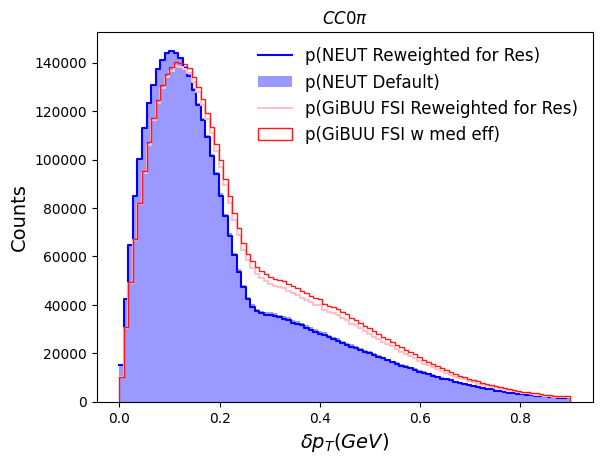

In [ ]:
# inputs
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]

# pion definition
is_pion = (abs(pdg_neut) == 211) | (pdg_neut == 111)
is_pionplus = (pdg_neut) == 211 
is_pionminus = (pdg_neut) == -211
is_pionzero = (pdg_neut) == 111

final_state = (chase_neut == 1)

# pion multiplicity per event
npi = ak.sum(is_pion & final_state, axis=1)
npip = ak.sum(is_pionplus & final_state, axis=1)
npim = ak.sum(is_pionminus & final_state, axis=1)
npiz = ak.sum(is_pionzero & final_state, axis=1)


# topology masks
mask_cc0pi = (npi == 0)
mask_cc1pi = (npi == 1)   
mask_cc1pip = (npip == 1) & (npim == 0) & (npiz == 0)   
mask_cc1pim = (npip == 0) & (npim == 1) & (npiz == 0)   
mask_cc1piz = (npip == 0) & (npim == 0) & (npiz == 1)   

# CC0π
dptf_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi = get_leading_proton_dpt(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    beam_index=flesp_index_neut[mask_cc0pi],
    mass_offset=0.035
)

# CC1π
dptf_neut_cc1pi,mode_neut_cc1pi,enf_neut_cc1pi = get_leading_proton_dpt(
    px_neut[mask_cc1pi],
    py_neut[mask_cc1pi],
    E_neut[mask_cc1pi],
    pdg_neut[mask_cc1pi],
    mode_neut[mask_cc1pi],
    truenuE_nuet[mask_cc1pi],
    chase_neut[mask_cc1pi],
    beam_index=flesp_index_neut[mask_cc1pi],
    mass_offset=0.035
) 

# CC1π+
dptf_neut_cc1pip,mode_neut_cc1pip,enf_neut_cc1pip = get_leading_proton_dpt(
    px_neut[mask_cc1pip],
    py_neut[mask_cc1pip],
    E_neut[mask_cc1pip],
    pdg_neut[mask_cc1pip],
    mode_neut[mask_cc1pip],
    truenuE_nuet[mask_cc1pip],
    chase_neut[mask_cc1pip],
    beam_index=flesp_index_neut[mask_cc1pip],
    mass_offset=0.035,
) 

hist1,bin1=np.histogram(dptf_neut_cc0pi[mode_neut_cc0pi==1],bins=100,range=(0,0.9))
hist2,bin1=np.histogram(dptf_neut_cc0pi[mode_neut_cc0pi==2],bins=100,range=(0,0.9))
hist3,bin1=np.histogram(dptf_neut_cc0pi[mode_neut_cc0pi==26],bins=100,range=(0,0.9))

hist4,bin1=np.histogram(dptf_neut_cc0pi[mode_neut_cc0pi==11], weights=bspl1(enf_neut_cc0pi[mode_neut_cc0pi==11]),bins=100,range=(0,0.9))
hist5,bin1=np.histogram(dptf_neut_cc0pi[mode_neut_cc0pi==12],weights=bspl2(enf_neut_cc0pi[mode_neut_cc0pi==12]),bins=100,range=(0,0.9))
hist6,bin1=np.histogram(dptf_neut_cc0pi[mode_neut_cc0pi==13], weights=bspl3(enf_neut_cc0pi[mode_neut_cc0pi==13]),bins=100,range=(0,0.9))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(dptf_neut_cc0pi,color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))

# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



# pion definition ( if needed)
is_pion_gibuu = (abs(ID_gibuu_w_med[idx2]) >= 100) & (abs(ID_gibuu_w_med[idx2]) <= 102)
is_pionplus_gibuu =  (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==1) 
is_pionminus_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==-1) 
is_pionzero_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==0) 
# final state definition
final_state_gibuu = (charge_gibuu_w_med[idx2] != 0)  # or your own condition

npi_gibuu = ak.sum(is_pion_gibuu, axis=1)
npip_gibuu = ak.sum(is_pionplus_gibuu, axis=1)
npim_gibuu = ak.sum(is_pionminus_gibuu, axis=1)
npiz_gibuu = ak.sum(is_pionzero_gibuu, axis=1)


mask_cc0pi_gibuu = (npi_gibuu == 0)
mask_cc1pi_gibuu = (npi_gibuu == 1)
mask_cc1pip_gibuu = (npip_gibuu == 1) & (npim_gibuu == 0) & (npiz_gibuu == 0)

dptf_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi = get_leading_proton_dpt_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],    
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
dptf_gibuu_w_med_cc1pi,mode_gibuu_cc1pi,enf_gibuu_cc1pi = get_leading_proton_dpt_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],    
    px_gibuu_w_med[idx2][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc1pi_gibuu],
    E_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mode_neut[mask_cc1pi_gibuu],
    truenuE_nuet[mask_cc1pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
dptf_gibuu_w_med_cc1pip,mode_gibuu_cc1pip,enf_gibuu_cc1pip = get_leading_proton_dpt_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],    
    px_gibuu_w_med[idx2][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][mask_cc1pip_gibuu],
    E_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mode_neut[mask_cc1pip_gibuu],
    truenuE_nuet[mask_cc1pip_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mass_offset=0.0,
    beam_index=0
)

hist1g,bin1=np.histogram(dptf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==1],bins=100,range=(0,0.9))
hist2g,bin1=np.histogram(dptf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==2],bins=100,range=(0,0.9))
hist3g,bin1=np.histogram(dptf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==26],bins=100,range=(0,0.9))

hist4g,bin1=np.histogram(dptf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==11], weights=bspl1(enf_gibuu_cc0pi[mode_gibuu_cc0pi==11]),bins=100,range=(0,0.9))
hist5g,bin1=np.histogram(dptf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==12],weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==12]),bins=100,range=(0,0.9))
hist6g,bin1=np.histogram(dptf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==13], weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==13]),bins=100,range=(0,0.9))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(dptf_gibuu_w_med_cc0pi,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,0.9))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta p_T(GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC0\pi$")

# print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))

Text(0.5, 1.0, '$CC1\\pi$')

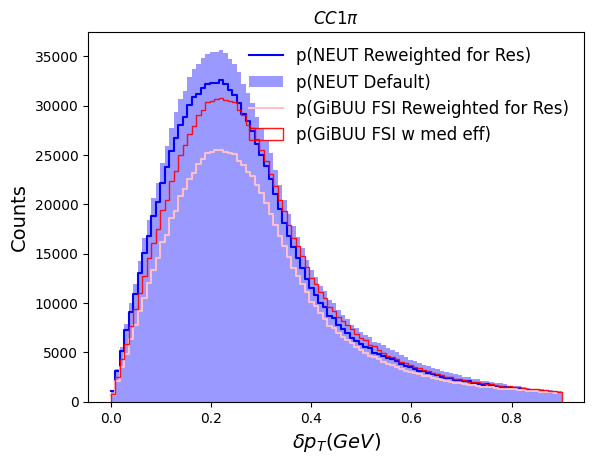

In [142]:
hist1,bin1=np.histogram(dptf_neut_cc1pi[mode_neut_cc1pi==1],bins=100,range=(0,0.9))
hist2,bin1=np.histogram(dptf_neut_cc1pi[mode_neut_cc1pi==2],bins=100,range=(0,0.9))
hist3,bin1=np.histogram(dptf_neut_cc1pi[mode_neut_cc1pi==26],bins=100,range=(0,0.9))
hist4,bin1=np.histogram(dptf_neut_cc1pi[mode_neut_cc1pi==11], weights=bspl1(enf_neut_cc1pi[mode_neut_cc1pi==11]),bins=100,range=(0,0.9))
hist5,bin1=np.histogram(dptf_neut_cc1pi[mode_neut_cc1pi==12],weights=bspl2(enf_neut_cc1pi[mode_neut_cc1pi==12]),bins=100,range=(0,0.9))
hist6,bin1=np.histogram(dptf_neut_cc1pi[mode_neut_cc1pi==13], weights=bspl3(enf_neut_cc1pi[mode_neut_cc1pi==13]),bins=100,range=(0,0.9))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(dptf_neut_cc1pi,color="blue",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
# plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(dptf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==1],bins=100,range=(0,0.9))
hist2g,bin1=np.histogram(dptf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==2],bins=100,range=(0,0.9))
hist3g,bin1=np.histogram(dptf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==26],bins=100,range=(0,0.9))

hist4g,bin1=np.histogram(dptf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==11], weights=bspl1(enf_gibuu_cc1pi[mode_gibuu_cc1pi==11]),bins=100,range=(0,0.9))
hist5g,bin1=np.histogram(dptf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==12],weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==12]),bins=100,range=(0,0.9))
hist6g,bin1=np.histogram(dptf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==13], weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==13]),bins=100,range=(0,0.9))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
# plt.hist(dptf_gibuu_wo_med_cc1pip,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))
plt.hist(dptf_gibuu_w_med_cc1pi,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,0.9))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta p_T(GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi$")

Text(0.5, 1.0, '$CC1\\pi+$')

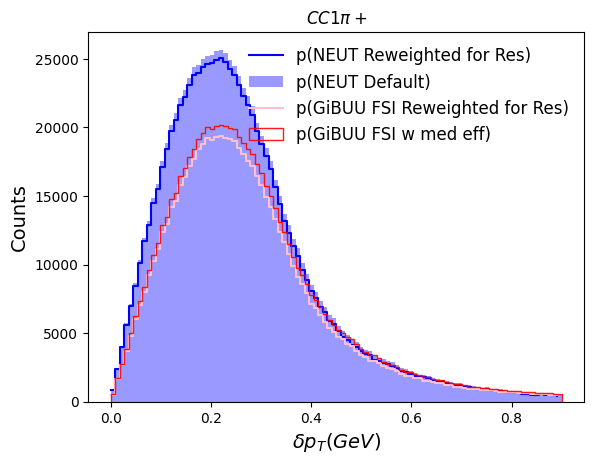

In [143]:
hist1,bin1=np.histogram(dptf_neut_cc1pip[mode_neut_cc1pip==1],bins=100,range=(0,0.9))
hist2,bin1=np.histogram(dptf_neut_cc1pip[mode_neut_cc1pip==2],bins=100,range=(0,0.9))
hist3,bin1=np.histogram(dptf_neut_cc1pip[mode_neut_cc1pip==26],bins=100,range=(0,0.9))
hist4,bin1=np.histogram(dptf_neut_cc1pip[mode_neut_cc1pip==11], weights=bspl1(enf_neut_cc1pip[mode_neut_cc1pip==11]),bins=100,range=(0,0.9))
hist5,bin1=np.histogram(dptf_neut_cc1pip[mode_neut_cc1pip==12],weights=bspl2(enf_neut_cc1pip[mode_neut_cc1pip==12]),bins=100,range=(0,0.9))
hist6,bin1=np.histogram(dptf_neut_cc1pip[mode_neut_cc1pip==13], weights=bspl3(enf_neut_cc1pip[mode_neut_cc1pip==13]),bins=100,range=(0,0.9))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(dptf_neut_cc1pip,color="blue",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
# plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(dptf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==1],bins=100,range=(0,0.9))
hist2g,bin1=np.histogram(dptf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==2],bins=100,range=(0,0.9))
hist3g,bin1=np.histogram(dptf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==26],bins=100,range=(0,0.9))

hist4g,bin1=np.histogram(dptf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==11], weights=bspl1(enf_gibuu_cc1pip[mode_gibuu_cc1pip==11]),bins=100,range=(0,0.9))
hist5g,bin1=np.histogram(dptf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==12],weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==12]),bins=100,range=(0,0.9))
hist6g,bin1=np.histogram(dptf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==13], weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==13]),bins=100,range=(0,0.9))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
# plt.hist(dptf_gibuu_wo_med_cc1pip,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))
plt.hist(dptf_gibuu_w_med_cc1pip,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,0.9))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta p_T(GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi+$")

## $\delta \alpha_T$

In [144]:
def get_leading_proton_dalphat(px, py, E, pdg, mode, nue, chase,beam_index, mass_offset=0.035):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    pt=np.sqrt(px*px+py*py)
    # proton selection (final state)
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))
    # proton selection (final state)
    proton_mask = (pdg == 2212) & (chase == 1) & (Ef > 0)
    row_idx = ak.local_index(px, axis=0)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]
    out3= pt[row_idx,beam_index]
    # ΔpT definition (your convention)
    dptx = px + out1
    dpty = py + out2
    dalpha_neut=(-out1*dptx-out2*dpty)/((out3)*(np.sqrt(dptx*dptx+dpty*dpty)))

    # apply mask
    dptx_p = dptx[proton_mask]
    dpty_p = dpty[proton_mask]
    Ef_p   = Ef[proton_mask]
    px_p=px[proton_mask]
    py_p=py[proton_mask]
    dalpha_neut_p=dalpha_neut[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]

    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    dptx_p = dptx_p[valid]
    dpty_p = dpty_p[valid]
    Ef_p   = Ef_p[valid]
    px_p = px_p[valid]
    py_p = py_p[valid]
    dalpha_neut_p=dalpha_neut_p[valid]    # leading proton index per event
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]    
    pt_p = np.sqrt(px_p*px_p+py_p*py_p)
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dptx_sorted = dptx_p[sorted_idx]
    dpty_sorted = dpty_p[sorted_idx]
    pt_p_sorted= pt_p[sorted_idx]
    px_p_sorted= px_p[sorted_idx]
    py_p_sorted= py_p[sorted_idx]
    dalpha_neut_p_sorted=dalpha_neut_p[sorted_idx]    


    dptx_lead = ak.firsts(dptx_sorted)
    dpty_lead = ak.firsts(dpty_sorted)
    pt_p_lead = ak.firsts(pt_p_sorted)
    px_p_lead = ak.firsts(px_p_sorted)
    py_p_lead = ak.firsts(py_p_sorted)
    dalpha_neut=ak.firsts(dalpha_neut_p_sorted)


    return dalpha_neut,ak.firsts(mode_p),ak.firsts(nue_p)

def get_leading_proton_dalphat_gibuu(px, py, px_all, py_all, E, pdg, mode, nue, charge, mass_offset=0.0, beam_index=0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    pt=np.sqrt(px*px+py*py)
    pt_all=np.sqrt(px_all*px_all+py_all*py_all)

    nue=nue*(ak.ones_like(Ef))
    mode=mode*(ak.ones_like(Ef))
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (Ef > 0)

    # ΔpT definition (your convention)
    dptx = px + px_all[:, beam_index]
    dpty = py + py_all[:, beam_index]
    dalpha_neut=(-px_all[:,beam_index]*dptx-py_all[:,beam_index]*dpty)/((pt_all[:,beam_index])*(np.sqrt(dptx*dptx+dpty*dpty)))

    # apply mask
    dptx_p = dptx[proton_mask]
    dpty_p = dpty[proton_mask]
    Ef_p   = Ef[proton_mask]
    px_p=px[proton_mask]
    py_p=py[proton_mask]
    dalpha_neut_p=dalpha_neut[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]    

    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    dptx_p = dptx_p[valid]
    dpty_p = dpty_p[valid]
    Ef_p   = Ef_p[valid]
    px_p = px_p[valid]
    py_p = py_p[valid]
    pt_p=np.sqrt(px_p*px_p+py_p*py_p)
    dalpha_neut_p=dalpha_neut_p[valid]    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]  

    dptx_sorted = dptx_p[sorted_idx]
    dpty_sorted = dpty_p[sorted_idx]
    pt_p_sorted= pt_p[sorted_idx]
    px_p_sorted= px_p[sorted_idx]
    py_p_sorted= py_p[sorted_idx]
    dalpha_neut_p_sorted=dalpha_neut_p[sorted_idx]


    dptx_lead = ak.firsts(dptx_sorted)
    dpty_lead = ak.firsts(dpty_sorted)
    pt_p_lead = ak.firsts(pt_p_sorted)
    px_p_lead = ak.firsts(px_p_sorted)
    py_p_lead = ak.firsts(py_p_sorted)

    dalpha_neut_lead=ak.firsts(dalpha_neut_p_sorted)

    return dalpha_neut_lead,ak.firsts(mode_p),ak.firsts(nue_p)

Text(0.5, 1.0, '$CC0\\pi$')

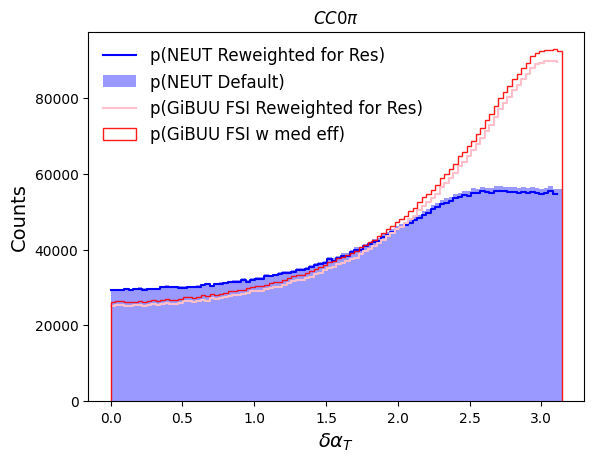

In [ ]:
# inputs
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]

# pion definition
is_pion = (abs(pdg_neut) == 211) | (pdg_neut == 111)
is_pionplus = (pdg_neut) == 211 
is_pionminus = (pdg_neut) == -211
is_pionzero = (pdg_neut) == 111

final_state = (chase_neut == 1)

# pion multiplicity per event
npi = ak.sum(is_pion & final_state, axis=1)
npip = ak.sum(is_pionplus & final_state, axis=1)
npim = ak.sum(is_pionminus & final_state, axis=1)
npiz = ak.sum(is_pionzero & final_state, axis=1)


# topology masks
mask_cc0pi = (npi == 0)
mask_cc1pi = (npi == 1)   
mask_cc1pip = (npip == 1) & (npim == 0) & (npiz == 0)   
mask_cc1pim = (npip == 0) & (npim == 1) & (npiz == 0)   
mask_cc1piz = (npip == 0) & (npim == 0) & (npiz == 1)   

# CC0π
dalphaf_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi = get_leading_proton_dalphat(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    flesp_index_neut[mask_cc0pi],   
    mass_offset=0.035
)

# CC1π
dalphaf_neut_cc1pi,mode_neut_cc1pi,enf_neut_cc1pi = get_leading_proton_dalphat(
    px_neut[mask_cc1pi],
    py_neut[mask_cc1pi],
    E_neut[mask_cc1pi],
    pdg_neut[mask_cc1pi],
    mode_neut[mask_cc1pi],
    truenuE_nuet[mask_cc1pi],
    chase_neut[mask_cc1pi],
    flesp_index_neut[mask_cc1pi],   
    mass_offset=0.035
) 

# CC1π+
dalphaf_neut_cc1pip,mode_neut_cc1pip,enf_neut_cc1pip = get_leading_proton_dalphat(
    px_neut[mask_cc1pip],
    py_neut[mask_cc1pip],
    E_neut[mask_cc1pip],
    pdg_neut[mask_cc1pip],
    mode_neut[mask_cc1pip],
    truenuE_nuet[mask_cc1pip],
    chase_neut[mask_cc1pip],
    flesp_index_neut[mask_cc1pip],   
    mass_offset=0.035
) 

hist1,bin1=np.histogram(np.arccos(dalphaf_neut_cc0pi[mode_neut_cc0pi==1]),bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(np.arccos(dalphaf_neut_cc0pi[mode_neut_cc0pi==2]),bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(np.arccos(dalphaf_neut_cc0pi[mode_neut_cc0pi==26]),bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(np.arccos(dalphaf_neut_cc0pi[mode_neut_cc0pi==11]), weights=bspl1(enf_neut_cc0pi[mode_neut_cc0pi==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(np.arccos(dalphaf_neut_cc0pi[mode_neut_cc0pi==12]),weights=bspl2(enf_neut_cc0pi[mode_neut_cc0pi==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(np.arccos(dalphaf_neut_cc0pi[mode_neut_cc0pi==13]), weights=bspl3(enf_neut_cc0pi[mode_neut_cc0pi==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(np.arccos(dalphaf_neut_cc0pi),color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))

# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



# pion definition ( if needed)
is_pion_gibuu = (abs(ID_gibuu_w_med[idx2]) >= 100) & (abs(ID_gibuu_w_med[idx2]) <= 102)
is_pionplus_gibuu =  (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==1) 
is_pionminus_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==-1) 
is_pionzero_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==0) 
# final state definition
final_state_gibuu = (charge_gibuu_w_med[idx2] != 0)  # or your own condition

npi_gibuu = ak.sum(is_pion_gibuu, axis=1)
npip_gibuu = ak.sum(is_pionplus_gibuu, axis=1)
npim_gibuu = ak.sum(is_pionminus_gibuu, axis=1)
npiz_gibuu = ak.sum(is_pionzero_gibuu, axis=1)


mask_cc0pi_gibuu = (npi_gibuu == 0)
mask_cc1pi_gibuu = (npi_gibuu == 1)
mask_cc1pip_gibuu = (npip_gibuu == 1) & (npim_gibuu == 0) & (npiz_gibuu == 0)

dalphaf_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi = get_leading_proton_dalphat_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],    
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
dalphaf_gibuu_w_med_cc1pi,mode_gibuu_cc1pi,enf_gibuu_cc1pi = get_leading_proton_dalphat_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    px_gibuu_w_med[idx2][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc1pi_gibuu],    
    E_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mode_neut[mask_cc1pi_gibuu],
    truenuE_nuet[mask_cc1pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
dalphaf_gibuu_w_med_cc1pip,mode_gibuu_cc1pip,enf_gibuu_cc1pip = get_leading_proton_dalphat_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    px_gibuu_w_med[idx2][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][mask_cc1pip_gibuu],    
    E_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mode_neut[mask_cc1pip_gibuu],
    truenuE_nuet[mask_cc1pip_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mass_offset=0.0,
    beam_index=0
)

hist1g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==1]),bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==2]),bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==26]),bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==11]), weights=bspl1(enf_gibuu_cc0pi[mode_gibuu_cc0pi==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==12]),weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==13]), weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(np.arccos(dalphaf_gibuu_w_med_cc0pi),color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta \alpha_T$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC0\pi$")

# # print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))

Text(0.5, 1.0, '$CC1\\pi$')

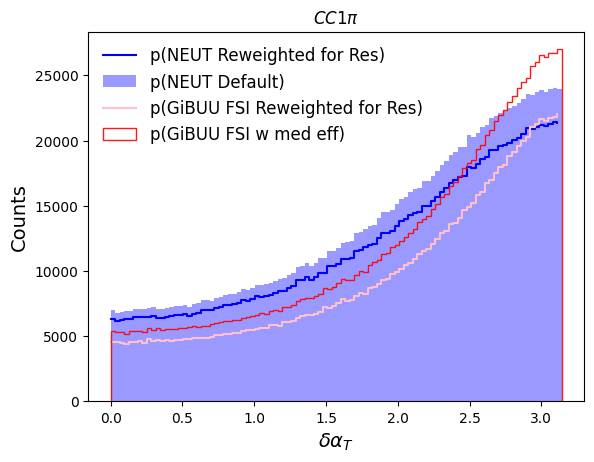

In [146]:
hist1,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pi[mode_neut_cc1pi==1]),bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pi[mode_neut_cc1pi==2]),bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pi[mode_neut_cc1pi==26]),bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pi[mode_neut_cc1pi==11]), weights=bspl1(enf_neut_cc1pi[mode_neut_cc1pi==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pi[mode_neut_cc1pi==12]),weights=bspl2(enf_neut_cc1pi[mode_neut_cc1pi==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pi[mode_neut_cc1pi==13]), weights=bspl3(enf_neut_cc1pi[mode_neut_cc1pi==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(np.arccos(dalphaf_neut_cc1pi),color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==1]),bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==2]),bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==26]),bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==11]), weights=bspl1(enf_gibuu_cc1pi[mode_gibuu_cc1pi==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==12]),weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==13]), weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(np.arccos(dalphaf_gibuu_w_med_cc1pi),color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta \alpha_T$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi$")
# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



Text(0.5, 1.0, '$CC1\\pi+$')

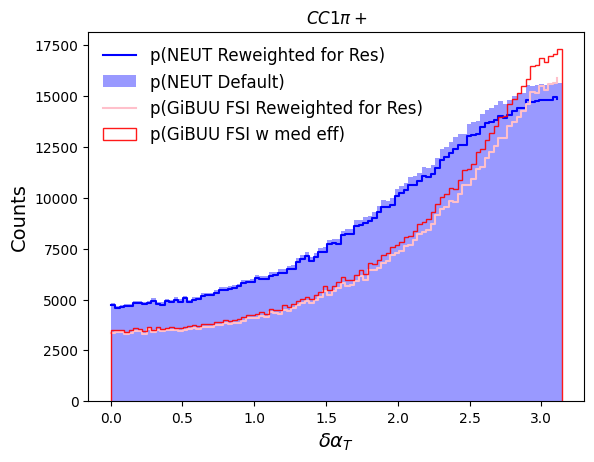

In [147]:
hist1,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pip[mode_neut_cc1pip==1]),bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pip[mode_neut_cc1pip==2]),bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pip[mode_neut_cc1pip==26]),bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pip[mode_neut_cc1pip==11]), weights=bspl1(enf_neut_cc1pip[mode_neut_cc1pip==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pip[mode_neut_cc1pip==12]),weights=bspl2(enf_neut_cc1pip[mode_neut_cc1pip==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(np.arccos(dalphaf_neut_cc1pip[mode_neut_cc1pip==13]), weights=bspl3(enf_neut_cc1pip[mode_neut_cc1pip==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(np.arccos(dalphaf_neut_cc1pip),color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==1]),bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==2]),bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==26]),bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==11]), weights=bspl1(enf_gibuu_cc1pip[mode_gibuu_cc1pip==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==12]),weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(np.arccos(dalphaf_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==13]), weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(np.arccos(dalphaf_gibuu_w_med_cc1pip),color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta \alpha_T$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi+$")
# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



## $\delta \phi_T$

In [148]:
def get_leading_proton_dphit(px, py, E, pdg,mode,nue, chase, beam_index, mass_offset=0.0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))
    row_idx = ak.local_index(px, axis=0)
    pt=np.sqrt(px*px+py*py)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]
    out3= pt[row_idx,beam_index]
    # proton selection (final state)
    proton_mask = (pdg == 2212) & (chase == 1) & (Ef > 0)

    # ΔpT definition (your convention)

    dphi=(-px*out1-py*out2)/((pt)*(np.sqrt(out1*out1+out2*out2)))

    # apply mask

    dphi_p= dphi[proton_mask]
    Ef_p   = Ef[proton_mask]
    px_p=px[proton_mask]
    py_p=py[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]  
    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    Ef_p   = Ef_p[valid]
    dphi_p   = dphi_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]  
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dphi_p_sorted= dphi_p[sorted_idx]

    dphi_p_lead = ak.firsts(dphi_p_sorted)


    return dphi_p_lead,ak.firsts(mode_p),ak.firsts(nue_p)

def get_leading_proton_dphit_gibuu(px, py,px_all, py_all, E, pdg,mode,nue, charge, mass_offset=0.0, beam_index=0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    pt=np.sqrt(px*px+py*py)
    pt_all=np.sqrt(px_all*px_all+py_all*py_all)

    nue=nue*(ak.ones_like(Ef))
    mode=mode*(ak.ones_like(Ef))
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (Ef > 0)
    dphi=(-px*px_all[:,beam_index]-py*py_all[:,beam_index])/((pt)*(np.sqrt(px_all[:,beam_index]*px_all[:,beam_index]+py_all[:,beam_index]*py_all[:,beam_index])))

    # apply mask

    dphi_p= dphi[proton_mask]
    Ef_p   = Ef[proton_mask]
    px_p=px[proton_mask]
    py_p=py[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]  
    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    Ef_p   = Ef_p[valid]
    dphi_p   = dphi_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]  
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dphi_p_sorted= dphi_p[sorted_idx]

    dphi_p_lead = ak.firsts(dphi_p_sorted)
    return dphi_p_lead,ak.firsts(mode_p),ak.firsts(nue_p)

/home/t2k/pingaldg/.local/lib/python3.9/site-packages/awkward/_nplikes/array_module.py:251: RuntimeWarning: invalid value encountered in divide
  return impl(*broadcasted_args, **(kwargs or {}))


Text(0.5, 1.0, '$CC0\\pi$')

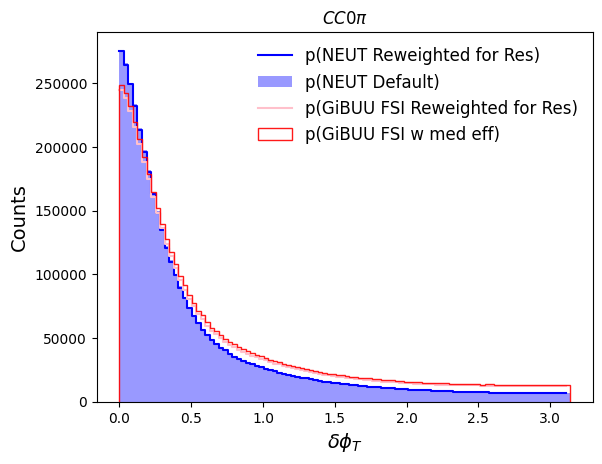

In [ ]:
# inputs
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]


# pion definition
is_pion = (abs(pdg_neut) == 211) | (pdg_neut == 111)
is_pionplus = (pdg_neut) == 211 
is_pionminus = (pdg_neut) == -211
is_pionzero = (pdg_neut) == 111

final_state = (chase_neut == 1)

# pion multiplicity per event
npi = ak.sum(is_pion & final_state, axis=1)
npip = ak.sum(is_pionplus & final_state, axis=1)
npim = ak.sum(is_pionminus & final_state, axis=1)
npiz = ak.sum(is_pionzero & final_state, axis=1)


# topology masks
mask_cc0pi = (npi == 0)
mask_cc1pi = (npi == 1)   
mask_cc1pip = (npip == 1) & (npim == 0) & (npiz == 0)   
mask_cc1pim = (npip == 0) & (npim == 1) & (npiz == 0)   
mask_cc1piz = (npip == 0) & (npim == 0) & (npiz == 1)   

# CC0π
dphif_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi = get_leading_proton_dphit(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],    
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    beam_index=flesp_index_neut[mask_cc0pi],
    mass_offset=0.035,
)

# CC1π
dphif_neut_cc1pi,mode_neut_cc1pi,enf_neut_cc1pi = get_leading_proton_dphit(
    px_neut[mask_cc1pi],
    py_neut[mask_cc1pi],
    E_neut[mask_cc1pi],
    pdg_neut[mask_cc1pi],
    mode_neut[mask_cc1pi],
    truenuE_nuet[mask_cc1pi],
    chase_neut[mask_cc1pi],
    beam_index=flesp_index_neut[mask_cc1pi],
    mass_offset=0.035,
) 

# CC1π+
dphif_neut_cc1pip,mode_neut_cc1pip,enf_neut_cc1pip = get_leading_proton_dphit(
    px_neut[mask_cc1pip],
    py_neut[mask_cc1pip],
    E_neut[mask_cc1pip],
    pdg_neut[mask_cc1pip],
    mode_neut[mask_cc1pip],
    truenuE_nuet[mask_cc1pip],
    chase_neut[mask_cc1pip],
    beam_index=flesp_index_neut[mask_cc1pip],
    mass_offset=0.035,
) 

hist1,bin1=np.histogram(np.arccos(dphif_neut_cc0pi[mode_neut_cc0pi==1]),bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(np.arccos(dphif_neut_cc0pi[mode_neut_cc0pi==2]),bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(np.arccos(dphif_neut_cc0pi[mode_neut_cc0pi==26]),bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(np.arccos(dphif_neut_cc0pi[mode_neut_cc0pi==11]), weights=bspl1(enf_neut_cc0pi[mode_neut_cc0pi==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(np.arccos(dphif_neut_cc0pi[mode_neut_cc0pi==12]),weights=bspl2(enf_neut_cc0pi[mode_neut_cc0pi==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(np.arccos(dphif_neut_cc0pi[mode_neut_cc0pi==13]), weights=bspl3(enf_neut_cc0pi[mode_neut_cc0pi==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(np.arccos(dphif_neut_cc0pi),color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))

# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



# pion definition ( if needed)
is_pion_gibuu = (abs(ID_gibuu_w_med[idx2]) >= 100) & (abs(ID_gibuu_w_med[idx2]) <= 102)
is_pionplus_gibuu =  (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==1) 
is_pionminus_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==-1) 
is_pionzero_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==0) 
# final state definition
final_state_gibuu = (charge_gibuu_w_med[idx2] != 0)  # or your own condition

npi_gibuu = ak.sum(is_pion_gibuu, axis=1)
npip_gibuu = ak.sum(is_pionplus_gibuu, axis=1)
npim_gibuu = ak.sum(is_pionminus_gibuu, axis=1)
npiz_gibuu = ak.sum(is_pionzero_gibuu, axis=1)


mask_cc0pi_gibuu = (npi_gibuu == 0)
mask_cc1pi_gibuu = (npi_gibuu == 1)
mask_cc1pip_gibuu = (npip_gibuu == 1) & (npim_gibuu == 0) & (npiz_gibuu == 0)

dphif_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi = get_leading_proton_dphit_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],    
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
dphif_gibuu_w_med_cc1pi,mode_gibuu_cc1pi,enf_gibuu_cc1pi = get_leading_proton_dphit_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    px_gibuu_w_med[idx2][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc1pi_gibuu],    
    E_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mode_neut[mask_cc1pi_gibuu],
    truenuE_nuet[mask_cc1pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
dphif_gibuu_w_med_cc1pip,mode_gibuu_cc1pip,enf_gibuu_cc1pip = get_leading_proton_dphit_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    px_gibuu_w_med[idx2][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][mask_cc1pip_gibuu],    
    E_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mode_neut[mask_cc1pip_gibuu],
    truenuE_nuet[mask_cc1pip_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mass_offset=0.0,
    beam_index=0
)

hist1g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==1]),bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==2]),bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==26]),bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==11]), weights=bspl1(enf_gibuu_cc0pi[mode_gibuu_cc0pi==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==12]),weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==13]), weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(np.arccos(dphif_gibuu_w_med_cc0pi),color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta \phi_T$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC0\pi$")

# # print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))

Text(0.5, 1.0, '$CC1\\pi$')

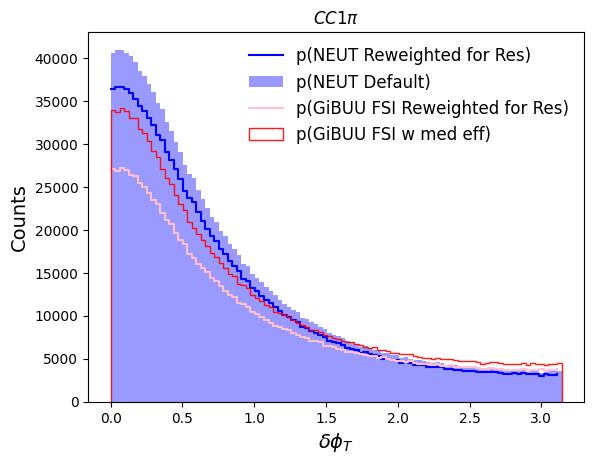

In [151]:
hist1,bin1=np.histogram(np.arccos(dphif_neut_cc1pi[mode_neut_cc1pi==1]),bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(np.arccos(dphif_neut_cc1pi[mode_neut_cc1pi==2]),bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(np.arccos(dphif_neut_cc1pi[mode_neut_cc1pi==26]),bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(np.arccos(dphif_neut_cc1pi[mode_neut_cc1pi==11]), weights=bspl1(enf_neut_cc1pi[mode_neut_cc1pi==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(np.arccos(dphif_neut_cc1pi[mode_neut_cc1pi==12]),weights=bspl2(enf_neut_cc1pi[mode_neut_cc1pi==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(np.arccos(dphif_neut_cc1pi[mode_neut_cc1pi==13]), weights=bspl3(enf_neut_cc1pi[mode_neut_cc1pi==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(np.arccos(dphif_neut_cc1pi),color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==1]),bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==2]),bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==26]),bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==11]), weights=bspl1(enf_gibuu_cc1pi[mode_gibuu_cc1pi==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==12]),weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==13]), weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(np.arccos(dphif_gibuu_w_med_cc1pi),color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta \phi_T$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi$")
# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))


Text(0.5, 1.0, '$CC1\\pi+$')

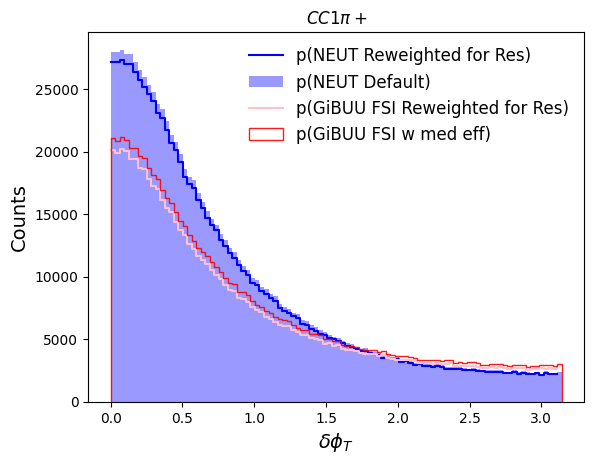

In [152]:
hist1,bin1=np.histogram(np.arccos(dphif_neut_cc1pip[mode_neut_cc1pip==1]),bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(np.arccos(dphif_neut_cc1pip[mode_neut_cc1pip==2]),bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(np.arccos(dphif_neut_cc1pip[mode_neut_cc1pip==26]),bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(np.arccos(dphif_neut_cc1pip[mode_neut_cc1pip==11]), weights=bspl1(enf_neut_cc1pip[mode_neut_cc1pip==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(np.arccos(dphif_neut_cc1pip[mode_neut_cc1pip==12]),weights=bspl2(enf_neut_cc1pip[mode_neut_cc1pip==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(np.arccos(dphif_neut_cc1pip[mode_neut_cc1pip==13]), weights=bspl3(enf_neut_cc1pip[mode_neut_cc1pip==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(np.arccos(dphif_neut_cc1pip),color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==1]),bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==2]),bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==26]),bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==11]), weights=bspl1(enf_gibuu_cc1pip[mode_gibuu_cc1pip==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==12]),weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(np.arccos(dphif_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==13]), weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(np.arccos(dphif_gibuu_w_med_cc1pip),color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$\delta \phi_T$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi+$")
# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



## Leading proton momentum

In [ ]:
def get_leading_proton_mom(px, py,pz, E, pdg,mode,nue, chase):

    # kinetic energy
    mass_offset=0.035
    Ef = E - 0.938 - mass_offset
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))
    # proton selection (final state)
    proton_mask = (pdg == 2212) & (chase == 1) & (Ef > 0)


    Ef_p   = Ef[proton_mask]
    px_p=px[proton_mask]
    py_p=py[proton_mask]
    pz_p=pz[proton_mask]
    ptot_p=px_p*px_p+py_p*py_p+pz_p*pz_p
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]  
    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    Ef_p   = Ef_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]  
    ptot_p=ptot_p[valid]
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    p_sorted= ak.firsts(ptot_p[sorted_idx])



    return np.sqrt(p_sorted),ak.firsts(mode_p),ak.firsts(nue_p)

def get_leading_proton_gibuu_mom(px, py,pz, E, pdg,mode,nue, charge, mass_offset=0.0):
    # kinetic energy
    Ef = E - 0.938 - mass_offset
    nue=nue*(ak.ones_like(Ef))
    mode=mode*(ak.ones_like(Ef))
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (Ef > 0)

    # apply mask
    ptot=px*px+py*py+pz*pz

    Ef_p  = Ef[proton_mask]
    px_p=px[proton_mask]
    py_p=py[proton_mask]
    pz_p=pz[proton_mask]
    mode_p=mode[proton_mask]
    nue_p=nue[proton_mask]  
    ptot_p=ptot[proton_mask]
    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    Ef_p   = Ef_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid] 
    ptot_p=ptot_p[valid]
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)
    p_sorted= ak.firsts(ptot_p[sorted_idx])


    return np.sqrt(p_sorted),ak.firsts(mode_p),ak.firsts(nue_p)

(0.0, 1.5)

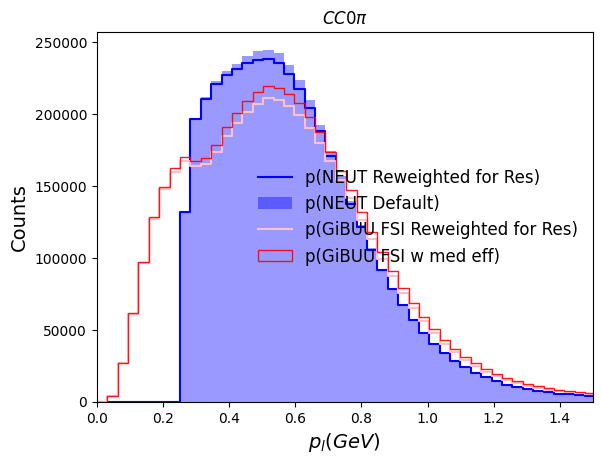

In [49]:
# inputs
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]


# pion definition
is_pion = (abs(pdg_neut) == 211) | (pdg_neut == 111)
is_pionplus = (pdg_neut) == 211 
is_pionminus = (pdg_neut) == -211
is_pionzero = (pdg_neut) == 111

final_state = (chase_neut == 1)

# pion multiplicity per event
npi = ak.sum(is_pion & final_state, axis=1)
npip = ak.sum(is_pionplus & final_state, axis=1)
npim = ak.sum(is_pionminus & final_state, axis=1)
npiz = ak.sum(is_pionzero & final_state, axis=1)


# topology masks
mask_cc0pi = (npi == 0)
mask_cc1pi = (npi == 1)   
mask_cc1pip = (npip == 1) & (npim == 0) & (npiz == 0)   
mask_cc1pim = (npip == 0) & (npim == 1) & (npiz == 0)   
mask_cc1piz = (npip == 0) & (npim == 0) & (npiz == 1)   

# CC0π
pl_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi = get_leading_proton_mom(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],    
    pz_neut[mask_cc0pi],     
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
)

# CC1π
pl_neut_cc1pi,mode_neut_cc1pi,enf_neut_cc1pi = get_leading_proton_mom(
    px_neut[mask_cc1pi],
    py_neut[mask_cc1pi],
    pz_neut[mask_cc1pi],     
    E_neut[mask_cc1pi],
    pdg_neut[mask_cc1pi],
    mode_neut[mask_cc1pi],
    truenuE_nuet[mask_cc1pi],
    chase_neut[mask_cc1pi],
) 

# CC1π+
pl_neut_cc1pip,mode_neut_cc1pip,enf_neut_cc1pip = get_leading_proton_mom(
    px_neut[mask_cc1pip],
    py_neut[mask_cc1pip],
    pz_neut[mask_cc1pip],     
    E_neut[mask_cc1pip],
    pdg_neut[mask_cc1pip],
    mode_neut[mask_cc1pip],
    truenuE_nuet[mask_cc1pip],
    chase_neut[mask_cc1pip],
) 

hist1,bin1=np.histogram(pl_neut_cc0pi[mode_neut_cc0pi==1],bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(pl_neut_cc0pi[mode_neut_cc0pi==2],bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(pl_neut_cc0pi[mode_neut_cc0pi==26],bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(pl_neut_cc0pi[mode_neut_cc0pi==11], weights=bspl1(enf_neut_cc0pi[mode_neut_cc0pi==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(pl_neut_cc0pi[mode_neut_cc0pi==12],weights=bspl2(enf_neut_cc0pi[mode_neut_cc0pi==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(pl_neut_cc0pi[mode_neut_cc0pi==13], weights=bspl3(enf_neut_cc0pi[mode_neut_cc0pi==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(pl_neut_cc0pi,color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))

# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))



# pion definition ( if needed)
is_pion_gibuu = (abs(ID_gibuu_w_med[idx2]) >= 100) & (abs(ID_gibuu_w_med[idx2]) <= 102)
is_pionplus_gibuu =  (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==1) 
is_pionminus_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==-1) 
is_pionzero_gibuu = (ID_gibuu_w_med[idx2]==101)  & (charge_gibuu_w_med[idx2] ==0) 
# final state definition
final_state_gibuu = (charge_gibuu_w_med[idx2] != 0)  # or your own condition

npi_gibuu = ak.sum(is_pion_gibuu, axis=1)
npip_gibuu = ak.sum(is_pionplus_gibuu, axis=1)
npim_gibuu = ak.sum(is_pionminus_gibuu, axis=1)
npiz_gibuu = ak.sum(is_pionzero_gibuu, axis=1)


mask_cc0pi_gibuu = (npi_gibuu == 0)
mask_cc1pi_gibuu = (npi_gibuu == 1)
mask_cc1pip_gibuu = (npip_gibuu == 1) & (npim_gibuu == 0) & (npiz_gibuu == 0)

pl_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi = get_leading_proton_gibuu_mom(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    pz_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mass_offset=0.0,
)
pl_gibuu_w_med_cc1pi,mode_gibuu_cc1pi,enf_gibuu_cc1pi = get_leading_proton_gibuu_mom(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    pz_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    E_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mode_neut[mask_cc1pi_gibuu],
    truenuE_nuet[mask_cc1pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pi_gibuu],
    mass_offset=0.0,
)
pl_gibuu_w_med_cc1pip,mode_gibuu_cc1pip,enf_gibuu_cc1pip = get_leading_proton_gibuu_mom(
    px_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    pz_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    E_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mode_neut[mask_cc1pip_gibuu],
    truenuE_nuet[mask_cc1pip_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc1pip_gibuu],
    mass_offset=0.0,
)

hist1g,bin1=np.histogram(pl_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==1],bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(pl_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==2],bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(pl_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==26],bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(pl_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==11], weights=bspl1(enf_gibuu_cc0pi[mode_gibuu_cc0pi==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(pl_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==12],weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(pl_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==13], weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(pl_gibuu_w_med_cc0pi,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$p_l(GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC0\pi$")
plt.xlim(0,1.5)


(0.0, 1.5)

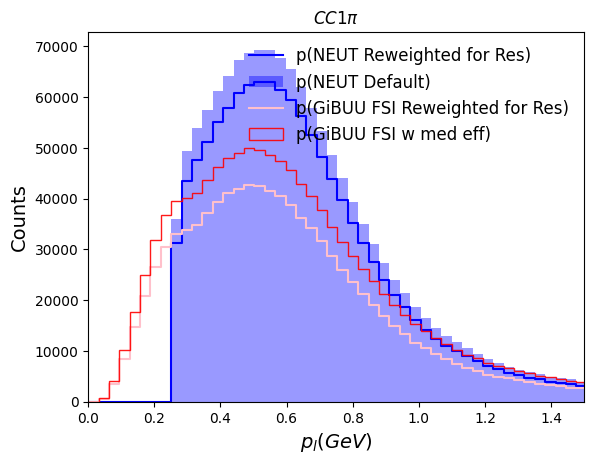

In [45]:
hist1,bin1=np.histogram(pl_neut_cc1pi[mode_neut_cc1pi==1],bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(pl_neut_cc1pi[mode_neut_cc1pi==2],bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(pl_neut_cc1pi[mode_neut_cc1pi==26],bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(pl_neut_cc1pi[mode_neut_cc1pi==11], weights=bspl1(enf_neut_cc1pi[mode_neut_cc1pi==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(pl_neut_cc1pi[mode_neut_cc1pi==12],weights=bspl2(enf_neut_cc1pi[mode_neut_cc1pi==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(pl_neut_cc1pi[mode_neut_cc1pi==13], weights=bspl3(enf_neut_cc1pi[mode_neut_cc1pi==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(pl_neut_cc1pi,color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(pl_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==1],bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(pl_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==2],bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(pl_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==26],bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(pl_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==11], weights=bspl1(enf_gibuu_cc1pi[mode_gibuu_cc1pi==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(pl_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==12],weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(pl_gibuu_w_med_cc1pi[mode_gibuu_cc1pi==13], weights=bspl4(enf_gibuu_cc1pi[mode_gibuu_cc1pi==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(pl_gibuu_w_med_cc1pi,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$p_l(GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi$")
plt.xlim(0.0,1.5)
# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))


Text(0.5, 1.0, '$CC1\\pi+$')

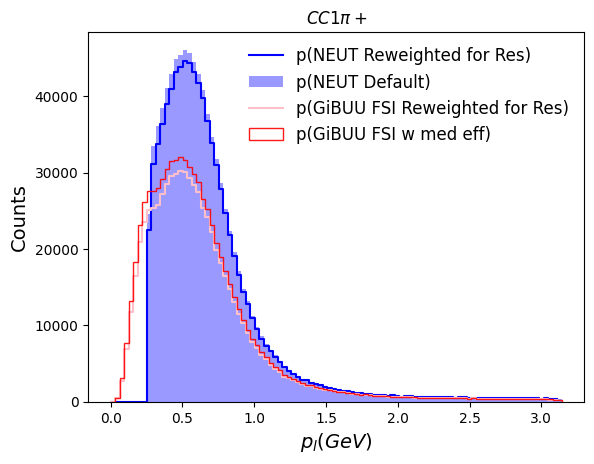

In [174]:
hist1,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==1],bins=100,range=(0,np.pi))
hist2,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==2],bins=100,range=(0,np.pi))
hist3,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==26],bins=100,range=(0,np.pi))

hist4,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==11], weights=bspl1(enf_neut_cc1pip[mode_neut_cc1pip==11]),bins=100,range=(0,np.pi))
hist5,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==12],weights=bspl2(enf_neut_cc1pip[mode_neut_cc1pip==12]),bins=100,range=(0,np.pi))
hist6,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==13], weights=bspl3(enf_neut_cc1pip[mode_neut_cc1pip==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.hist(pl_neut_cc1pip,color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
hist1g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==1],bins=100,range=(0,np.pi))
hist2g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==2],bins=100,range=(0,np.pi))
hist3g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==26],bins=100,range=(0,np.pi))

hist4g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==11], weights=bspl1(enf_gibuu_cc1pip[mode_gibuu_cc1pip==11]),bins=100,range=(0,np.pi))
hist5g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==12],weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==12]),bins=100,range=(0,np.pi))
hist6g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==13], weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==13]),bins=100,range=(0,np.pi))
# # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
plt.hist(pl_gibuu_w_med_cc1pip,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$p_l(GeV)$",fontsize=14)
plt.ylabel(r"Counts",fontsize=14)
plt.title(r"$CC1\pi+$")
# # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))


/home/t2k/pingaldg/.local/lib/python3.9/site-packages/awkward/_nplikes/array_module.py:251: RuntimeWarning: invalid value encountered in divide
  return impl(*broadcasted_args, **(kwargs or {}))


Text(0.5, 0, '$p_l(GeV)$')

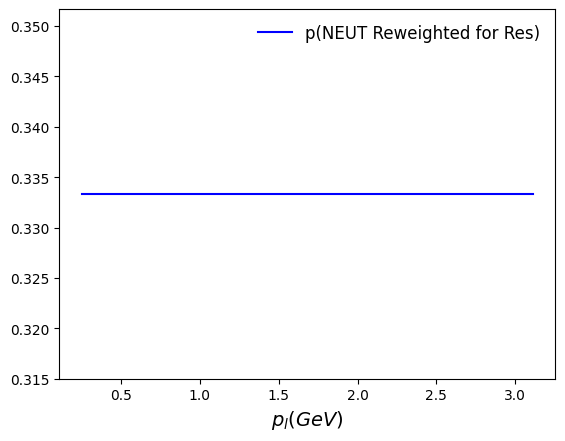

In [188]:
# hist1,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==1],bins=100,range=(0,np.pi))
# hist2,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==2],bins=100,range=(0,np.pi))
# hist3,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==26],bins=100,range=(0,np.pi))
hist44,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==11],bins=100,range=(0,np.pi))
hist4,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==11], weights=3.0*np.ones(len(enf_neut_cc1pip[mode_neut_cc1pip==11])),bins=100,range=(0,np.pi))
# hist5,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==12],weights=bspl2(enf_neut_cc1pip[mode_neut_cc1pip==12]),bins=100,range=(0,np.pi))
# hist6,bin1=np.histogram(pl_neut_cc1pip[mode_neut_cc1pip==13], weights=bspl3(enf_neut_cc1pip[mode_neut_cc1pip==13]),bins=100,range=(0,np.pi))
# plt.step(bin1[-1], hist1+hist2,hist3,where="post")
# plt.step(bin1[:-1],hist4, label="p(NEUT Reweighted for Res)", color="blue", where="post")
plt.step(bin1[:-1],hist44/hist4, label="p(NEUT Reweighted for Res)", color="blue", where="post")

# plt.hist(pl_neut_cc1pip,color="blue",bins=100, alpha=0.4,label="p(NEUT Default)",range=(0,np.pi))
# # # plt.hist(dptf_neut_cc1pi,color="red",bins=100,alpha=0.4,label="p(NEUT Default)",range=(0,0.9))
# hist1g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==1],bins=100,range=(0,np.pi))
# hist2g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==2],bins=100,range=(0,np.pi))
# hist3g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==26],bins=100,range=(0,np.pi))

# hist4g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==11], weights=bspl1(enf_gibuu_cc1pip[mode_gibuu_cc1pip==11]),bins=100,range=(0,np.pi))
# hist5g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==12],weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==12]),bins=100,range=(0,np.pi))
# hist6g,bin1=np.histogram(pl_gibuu_w_med_cc1pip[mode_gibuu_cc1pip==13], weights=bspl4(enf_gibuu_cc1pip[mode_gibuu_cc1pip==13]),bins=100,range=(0,np.pi))
# # # plt.step(bin1[-1], hist1+hist2,hist3,where="post")
# plt.step(bin1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="post")
# plt.hist(pl_gibuu_w_med_cc1pip,color="red",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w med eff)",range=(0,np.pi))

plt.legend(fontsize=12,framealpha=0.0)
plt.xlabel(r"$p_l(GeV)$",fontsize=14)
# plt.ylabel(r"Counts",fontsize=14)
 # # plt.hist(dptf_gibuu_wo_med_cc0pi,color="blue",bins=100,alpha=0.9,histtype='step',label="p(GiBUU FSI w/o med eff)",range=(0,0.9))


## Transparency

[0, 0, 8.81e+04, 3.07e+05, 3.78e+05, ..., 7.13e+04, 4.1e+04, 2.38e+04, 1.48e+04] [0, 188, 6.65e+03, 8.35e+04, ..., 7.67e+04, 4.47e+04, 2.63e+04, 1.65e+04] [31, 1.1e+04, 1.68e+05, 4.26e+05, ..., 1.21e+05, 7.27e+04, 4.43e+04, 2.84e+04]


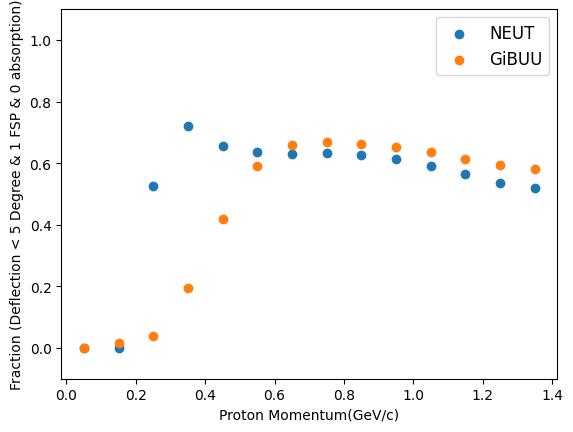

In [26]:
bins_array=np.arange(0.0,1.50,0.1)
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
is_good_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
    # (el_arr<40*np.pi/180) 
)
is_bad_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 0)

)
np_proton_event=ak.sum(is_good_proton, axis=1) > 0

E_evt = E_shift[np_proton_event]
proton_mask_evt = is_good_proton[np_proton_event]
proton_mask_evt2 = is_bad_proton[np_proton_event]

E_sel = E_evt[proton_mask_evt]
pxout_sel=px_arr[np_proton_event][proton_mask_evt]
pyout_sel=py_arr[np_proton_event][proton_mask_evt]
pzout_sel=pz_arr[np_proton_event][proton_mask_evt]
pdg_sel=pdg_arr[np_proton_event][proton_mask_evt]
chase_evt2=chase_arr[np_proton_event][proton_mask_evt]
chase_evt3=chase_arr[np_proton_event][proton_mask_evt2]


has_proton = ak.num(E_sel) > 0
E_sel = E_sel[has_proton]
px_sel = pxout_sel[has_proton]
py_sel = pyout_sel[has_proton]
pz_sel = pzout_sel[has_proton]
pdg_sel=pdg_sel[has_proton]

sorted_idx=ak.argsort(E_sel,axis=1,ascending=False)

E_sel=ak.firsts(E_sel[sorted_idx])
px_sel=ak.firsts(px_sel[sorted_idx])
py_sel=ak.firsts(py_sel[sorted_idx])
pz_sel=ak.firsts(pz_sel[sorted_idx])

E_evt = E_primary[np_proton_event]
px_evt= px_arr[:,3][np_proton_event]
py_evt= py_arr[:,3][np_proton_event]
pz_evt= pz_arr[:,3][np_proton_event]

def angout(px_arrx,py_arrx,pz_arrx):
    return np.arctan2(np.sqrt(px_arrx*px_arrx+py_arrx*py_arrx),pz_arrx)

maskp=mode_arr==1
mask_trans=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=5*np.pi/180
mask_trans2=ak.num(chase_evt2,axis=1)==1
mask_trans3=ak.num(chase_evt3,axis=1)==0
# mask_trans3=
# mask_trans3=
# maskel=(el_arr>20*np.pi/180) & (el_arr<40*np.pi/180)
mom_trans=np.sqrt(px_evt[mask_trans&mask_trans2&mask_trans3]*px_evt[mask_trans&mask_trans2&mask_trans3]+py_evt[mask_trans&mask_trans2&mask_trans3]*py_evt[mask_trans&mask_trans2&mask_trans3]+pz_evt[mask_trans&mask_trans2&mask_trans3]*pz_evt[mask_trans&mask_trans2&mask_trans3])
hist1,bins1=np.histogram(mom_trans,bins=bins_array, range=(0.2,1.5))
hist2,bins2=np.histogram(np.sqrt(px_arr[maskp][:,3]*px_arr[maskp][:,3]+py_arr[maskp][:,3]*py_arr[maskp][:,3]+pz_arr[maskp][:,3]*pz_arr[maskp][:,3]), bins=bins_array,range=(0.,1.5))

binc=(bins1[1:]+bins1[:-1])/2


E_arr3 = E_gibuu_w_med[idx2][:,2:]
ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
E_shift3 = E_arr3 - 0.938
E_primary_gibuu=E_primary
el_arrg=el_arr
is_proton3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 1) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)
# maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
np_proton_event3=ak.sum(is_proton3, axis=1) == 1
proton_mask_evt3 = is_proton3[np_proton_event3]

# E_evt_gibuu = E_primary_gibuu[np_proton_event3]
E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
has_gibuu_proton = ak.num(E_gibuu_sel,axis=1) > 0

E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]

sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)

E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])

E_evt3 = E_primary[np_proton_event3]
px_evt3= px_arr[:,3][np_proton_event3]
py_evt3= py_arr[:,3][np_proton_event3]
pz_evt3= pz_arr[:,3][np_proton_event3]

mask_trans_gibuu=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=5*np.pi/180
mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu]*px_evt3[mask_trans_gibuu]+py_evt3[mask_trans_gibuu]*py_evt3[mask_trans_gibuu]+pz_evt3[mask_trans_gibuu]*pz_evt3[mask_trans_gibuu])

hist11,bins11=np.histogram(mom_trans_gibuu,bins=bins_array,range=(0.,1.5))


# # E_evt3 = E_shift3[no_pion_evt3 & np_proton_event3]
# # mask_evt3 = is_proton3[no_pion_evt3 & np_proton_event3]

plt.scatter(binc,hist1/hist2, label="NEUT")
plt.ylim(-0.1,1.1)
plt.scatter(binc,hist11/hist2, label="GiBUU")
plt.legend(fontsize=12)
plt.ylabel("Fraction (Deflection < 5 Degree & 1 FSP & 0 absorption)")
plt.xlabel("Proton Momentum(GeV/c)")
# # E_sel3 = E_evt3[mask_evt3]


# # has_proton3 = ak.num(E_sel3) > 0
# # E_sel3 = E_sel3[has_proton3]


# # lead_E_gibuu_w_med_0pi = ak.max(E_sel3, axis=1)

# # plt.hist(
# #     ak.to_numpy(lead_E_gibuu_w_med_0pi),
# #     bins=bins_array,
# #     alpha=1,
# #     histtype="step",
# #     color="red",
# #     label="GIBUU w med"
# # )
print(hist1,hist11,hist2)

In [10]:
chase_evt3

<Array [[], [], [], [], [], ..., [], [], [], []] type='3456668 * var * int32'>

In [93]:
np.unique(ak.flatten(chase_arr[np_proton_event]))

<Array [0, 1] type='2 * int32'>

In [102]:
ak.num(chase_evt2)

<Array [0, 0, 0, 0, 0, 0, 0, ..., 1, 0, 1, 0, 0, 0, 0] type='3456668 * int64'>

[0, 0, 2.6e+03, 6.45e+04, 1.45e+05, ..., 4.05e+04, 2.58e+04, 1.65e+04, 1.08e+04] [0, 2.16e+03, 7.34e+04, 3.09e+05, ..., 3.92e+04, 2.46e+04, 1.56e+04, 1.02e+04] [31, 1.1e+04, 1.68e+05, 4.26e+05, ..., 1.21e+05, 7.27e+04, 4.43e+04, 2.84e+04]


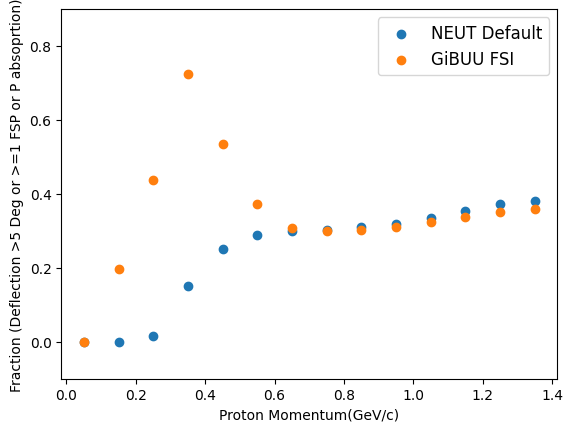

In [21]:
bins_array=np.arange(0.0,1.50,0.1)
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
is_good_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
    # (el_arr<40*np.pi/180) 
)

is_bad_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 0)

)
np_proton_event=ak.sum(is_good_proton, axis=1) > 0

E_evt = E_shift[np_proton_event]
proton_mask_evt = is_good_proton[np_proton_event]
E_sel = E_evt[proton_mask_evt]
pxout_sel=px_arr[np_proton_event][proton_mask_evt]
pyout_sel=py_arr[np_proton_event][proton_mask_evt]
pzout_sel=pz_arr[np_proton_event][proton_mask_evt]
pdg_sel=pdg_arr[np_proton_event][proton_mask_evt]
has_proton = ak.num(E_sel,axis=1) > 0
E_sel = E_sel[has_proton]
px_sel = pxout_sel[has_proton]
py_sel = pyout_sel[has_proton]
pz_sel = pzout_sel[has_proton]
pdg_sel=pdg_sel[has_proton]
proton_mask_evt = is_good_proton[np_proton_event]
proton_mask_evt2 = is_bad_proton[np_proton_event]
chase_evt2=chase_arr[np_proton_event][proton_mask_evt]
chase_evt3=chase_arr[np_proton_event][proton_mask_evt2]
sorted_idx=ak.argsort(E_sel,axis=1,ascending=False)

E_sel=ak.firsts(E_sel[sorted_idx])
px_sel=ak.firsts(px_sel[sorted_idx])
py_sel=ak.firsts(py_sel[sorted_idx])
pz_sel=ak.firsts(pz_sel[sorted_idx])

E_evt = E_primary[np_proton_event]
px_evt= px_arr[:,3][np_proton_event]
py_evt= py_arr[:,3][np_proton_event]
pz_evt= pz_arr[:,3][np_proton_event]

def angout(px_arrx,py_arrx,pz_arrx):
    return np.arctan2(np.sqrt(px_arrx*px_arrx+py_arrx*py_arrx),pz_arrx)

maskp=mode_arr==1
mask_trans=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))>5*np.pi/180
mask_trans2=ak.num(chase_evt2,axis=1)>1
mask_trans3=ak.num(chase_evt3,axis=1)>0
# maskel=(el_arr>20*np.pi/180) & (el_arr<40*np.pi/180)
mom_trans=np.sqrt(px_evt[mask_trans&(mask_trans2|mask_trans3)]*px_evt[mask_trans&(mask_trans2|mask_trans3)]+py_evt[mask_trans&(mask_trans2|mask_trans3)]*py_evt[mask_trans&(mask_trans2|mask_trans3)]+pz_evt[mask_trans&(mask_trans2|mask_trans3)]*pz_evt[mask_trans&(mask_trans2|mask_trans3)])
hist1,bins1=np.histogram(mom_trans,bins=bins_array, range=(0.2,1.5))
hist2,bins2=np.histogram(np.sqrt(px_arr[maskp][:,3]*px_arr[maskp][:,3]+py_arr[maskp][:,3]*py_arr[maskp][:,3]+pz_arr[maskp][:,3]*pz_arr[maskp][:,3]), bins=bins_array,range=(0.,1.5))

binc=(bins1[1:]+bins1[:-1])/2


E_arr3 = E_gibuu_w_med[idx2][:,2:]
ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
E_shift3 = E_arr3 - 0.938
E_primary_gibuu=E_primary
el_arrg=el_arr
is_proton3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 1) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)
# maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
np_proton_event3=ak.sum(is_proton3, axis=1) >= 1

proton_mask_evt3 = is_proton3[np_proton_event3]

# E_evt_gibuu = E_primary_gibuu[np_proton_event3]
E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
has_gibuu_proton = ak.num(E_gibuu_sel) > 0

E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]

sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)

E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])

E_evt3 = E_primary[np_proton_event3]
px_evt3= px_arr[:,3][np_proton_event3]
py_evt3= py_arr[:,3][np_proton_event3]
pz_evt3= pz_arr[:,3][np_proton_event3]

mask_trans_gibuu=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>5*np.pi/180
mask_trans_gibuu2=has_gibuu_proton>1

mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu | mask_trans_gibuu2]*px_evt3[mask_trans_gibuu| mask_trans_gibuu2]+py_evt3[mask_trans_gibuu| mask_trans_gibuu2]*py_evt3[mask_trans_gibuu| mask_trans_gibuu2]+pz_evt3[mask_trans_gibuu| mask_trans_gibuu2]*pz_evt3[mask_trans_gibuu| mask_trans_gibuu2])
hist11,bins11=np.histogram(mom_trans_gibuu,bins=bins_array,range=(0.,1.5))


# # E_evt3 = E_shift3[no_pion_evt3 & np_proton_event3]
# # mask_evt3 = is_proton3[no_pion_evt3 & np_proton_event3]

plt.scatter(binc,hist1/hist2, label="NEUT Default")
plt.ylim(-0.1,0.9)
plt.scatter(binc,hist11/hist2, label="GiBUU FSI")
plt.legend(fontsize=12)
plt.ylabel("Fraction (Deflection >5 Deg or >=1 FSP or P absoprtion)")
plt.xlabel("Proton Momentum(GeV/c)")
# # E_sel3 = E_evt3[mask_evt3]


# # has_proton3 = ak.num(E_sel3) > 0
# # E_sel3 = E_sel3[has_proton3]


# # lead_E_gibuu_w_med_0pi = ak.max(E_sel3, axis=1)

# # plt.hist(
# #     ak.to_numpy(lead_E_gibuu_w_med_0pi),
# #     bins=bins_array,
# #     alpha=1,
# #     histtype="step",
# #     color="red",
# #     label="GIBUU w med"
# # )
print(hist1,hist11,hist2)

[4.22e+05, 4.33e+05, 3.8e+05, 3.08e+05, 2.35e+05, ..., 1.02e+03, 896, 796, 693] [9.8e+04, 2.87e+05, 3.58e+05, 3.16e+05, 2.43e+05, ..., 1.06e+03, 910, 784, 712] [5.77e+05, 6.63e+05, 6e+05, 4.88e+05, ..., 1.78e+03, 1.54e+03, 1.33e+03]


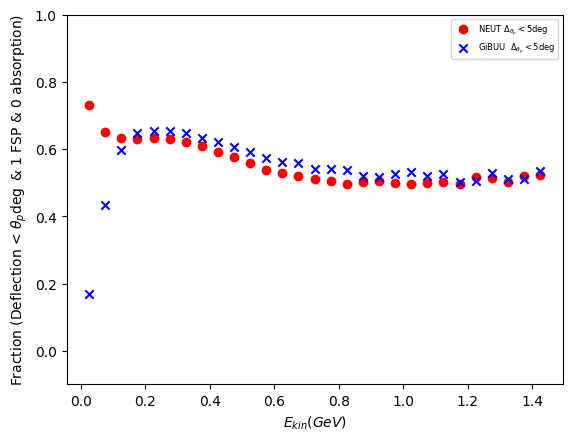

In [59]:
bins_array=np.arange(0.0,1.50,0.05)
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
is_good_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
    # (el_arr<40*np.pi/180) 
)
is_bad_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 0)

)
np_proton_event=ak.sum(is_good_proton, axis=1) > 0

E_evt = E_shift[np_proton_event]
proton_mask_evt = is_good_proton[np_proton_event]
E_sel = E_evt[proton_mask_evt]
pxout_sel=px_arr[np_proton_event][proton_mask_evt]
pyout_sel=py_arr[np_proton_event][proton_mask_evt]
pzout_sel=pz_arr[np_proton_event][proton_mask_evt]
pdg_sel=pdg_arr[np_proton_event][proton_mask_evt]
has_proton = ak.num(E_sel) > 0
E_sel = E_sel[has_proton]
px_sel = pxout_sel[has_proton]
py_sel = pyout_sel[has_proton]
pz_sel = pzout_sel[has_proton]
pdg_sel=pdg_sel[has_proton]
proton_mask_evt = is_good_proton[np_proton_event]
proton_mask_evt2 = is_bad_proton[np_proton_event]
chase_evt2=chase_arr[np_proton_event][proton_mask_evt]
chase_evt3=chase_arr[np_proton_event][proton_mask_evt2]
sorted_idx=ak.argsort(E_sel,axis=1,ascending=False)

E_sel=ak.firsts(E_sel[sorted_idx])
px_sel=ak.firsts(px_sel[sorted_idx])
py_sel=ak.firsts(py_sel[sorted_idx])
pz_sel=ak.firsts(pz_sel[sorted_idx])

E_evt = E_primary[np_proton_event]
px_evt= px_arr[:,3][np_proton_event]
py_evt= py_arr[:,3][np_proton_event]
pz_evt= pz_arr[:,3][np_proton_event]

def angout(px_arrx,py_arrx,pz_arrx):
    return np.arctan2(np.sqrt(px_arrx*px_arrx+py_arrx*py_arrx),pz_arrx)

maskp=mode_arr==1
mask_trans=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=5*np.pi/180
mask_trans2=ak.num(chase_evt2)==1
mask_trans3=ak.num(chase_evt3)==0
# maskel=(el_arr>20*np.pi/180) & (el_arr<40*np.pi/180)
mom_trans=np.sqrt(px_evt[mask_trans&mask_trans2&mask_trans3]*px_evt[mask_trans&mask_trans2&mask_trans3]+py_evt[mask_trans&mask_trans2&mask_trans3]*py_evt[mask_trans&mask_trans2&mask_trans3]+pz_evt[mask_trans&mask_trans2&mask_trans3]*pz_evt[mask_trans&mask_trans2&mask_trans3])
hist1,bins1=np.histogram(E_evt[mask_trans&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))
hist2,bins2=np.histogram(E_primary[maskp], bins=bins_array,range=(0.,1.5))

mask_trans4=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=10*np.pi/180
mask_trans5=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=15*np.pi/180
mask_trans6=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=20*np.pi/180

hist3,bins1=np.histogram(E_evt[mask_trans4&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))
hist4,bins1=np.histogram(E_evt[mask_trans5&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))
hist5,bins1=np.histogram(E_evt[mask_trans6&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))



binc=(bins1[1:]+bins1[:-1])/2


E_arr3 = E_gibuu_w_med[idx2][:,2:]
ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
E_shift3 = E_arr3 - 0.938
E_primary_gibuu=E_primary
el_arrg=el_arr
is_proton3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 1) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)

is_neutron3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 0) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)
# maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
np_proton_event3=ak.sum(is_proton3, axis=1) == 1
proton_mask_evt3 = is_proton3[np_proton_event3]
neutron_mask_evt3 = is_neutron3[np_proton_event3]

# E_evt_gibuu = E_primary_gibuu[np_proton_event3]
E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
has_gibuu_proton = ak.num(E_gibuu_sel) > 0
has_gibuu_neutron = ak.num(E_shift3[np_proton_event3][neutron_mask_evt3]) > 0

E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]

sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)

E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])

E_evt3 = E_primary[np_proton_event3]
px_evt3= px_arr[:,3][np_proton_event3]
py_evt3= py_arr[:,3][np_proton_event3]
pz_evt3= pz_arr[:,3][np_proton_event3]

mask_trans_gibuu=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=5*np.pi/180
mask_trans_gibuu_neutron=has_gibuu_neutron==0

mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu]*px_evt3[mask_trans_gibuu]+py_evt3[mask_trans_gibuu]*py_evt3[mask_trans_gibuu]+pz_evt3[mask_trans_gibuu]*pz_evt3[mask_trans_gibuu])

hist11,bins11=np.histogram(E_evt3[mask_trans_gibuu&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))


mask_trans_gibuu2=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=10*np.pi/180
mask_trans_gibuu3=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=15*np.pi/180
mask_trans_gibuu4=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=20*np.pi/180

hist22,bins11=np.histogram(E_evt3[mask_trans_gibuu&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
hist33,bins11=np.histogram(E_evt3[mask_trans_gibuu3&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
hist44,bins11=np.histogram(E_evt3[mask_trans_gibuu4&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))


# # E_evt3 = E_shift3[no_pion_evt3 & np_proton_event3]
# # mask_evt3 = is_proton3[no_pion_evt3 & np_proton_event3]

plt.scatter(binc,hist1/hist2,color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}<5\deg$")
# plt.scatter(binc,hist3/hist2,color="green",marker="o", label=r"NEUT $\Delta_{\theta_p}<10\deg$")
# plt.scatter(binc,hist4/hist2,color="blue",marker="o", label=r"NEUT $\Delta_{\theta_p}<15\deg$")
# plt.scatter(binc,hist5/hist2,color="pink",marker="o", label=r"NEUT $\Delta_{\theta_p}<20\deg$")
# plt.plot(binc,hist5/hist2,color="grey")

plt.ylim(-0.1,1.0)
plt.scatter(binc,hist11/hist2, color="blue",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<5\deg$")
# plt.scatter(binc,hist22/hist2,color="green",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<10\deg$")
# plt.scatter(binc,hist33/hist2,color="blue",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<15\deg$")
# plt.scatter(binc,hist44/hist2,color="pink",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<20\deg$")

# plt.plot(binc,hist11/hist2, color="red")
# plt.plot(binc,hist22/hist2,color="green")
# plt.plot(binc,hist33/hist2,color="blue")
# plt.plot(binc,hist44/hist2,color="pink")

plt.legend(fontsize=6)
plt.ylabel(r"Fraction (Deflection < $\theta_p \deg$ & 1 FSP & 0 absorption)")
plt.xlabel(r"$E_{kin}(GeV)$")
# # E_sel3 = E_evt3[mask_evt3]


# # has_proton3 = ak.num(E_sel3) > 0
# # E_sel3 = E_sel3[has_proton3]


# # lead_E_gibuu_w_med_0pi = ak.max(E_sel3, axis=1)

# # plt.hist(
# #     ak.to_numpy(lead_E_gibuu_w_med_0pi),
# #     bins=bins_array,
# #     alpha=1,
# #     histtype="step",
# #     color="red",
# #     label="GIBUU w med"
# # )
print(hist1,hist11,hist2)

[8.54e+04, 1.93e+05, 1.98e+05, 1.67e+05, 1.28e+05, ..., 928, 863, 715, 617] [3.87e+05, 3.48e+05, 2.25e+05, 1.59e+05, 1.2e+05, ..., 845, 793, 682, 550] [5.77e+05, 6.63e+05, 6e+05, 4.88e+05, ..., 1.78e+03, 1.54e+03, 1.33e+03]


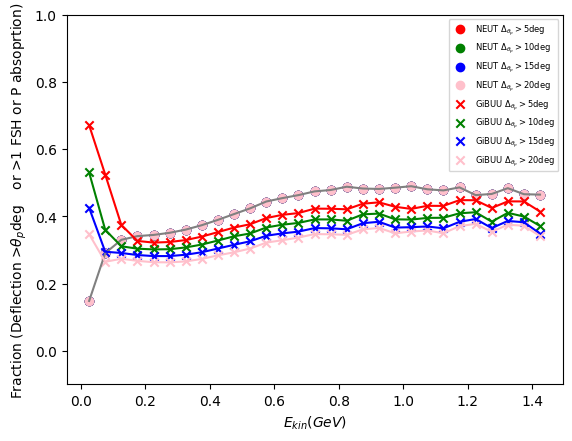

In [55]:
bins_array=np.arange(0.0,1.50,0.05)
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
is_good_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
   
    # (el_arr<40*np.pi/180) 
)
is_good_neutron = ( (mode_arr==1) &
    (pdg_arr == 2112) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
   
    # (el_arr<40*np.pi/180) 
)
is_bad_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 0)

)
np_proton_event=ak.sum(is_good_proton, axis=1) > 0

E_evt = E_shift[np_proton_event]
proton_mask_evt = is_good_proton[np_proton_event]
E_sel = E_evt[proton_mask_evt]
pxout_sel=px_arr[np_proton_event][proton_mask_evt]
pyout_sel=py_arr[np_proton_event][proton_mask_evt]
pzout_sel=pz_arr[np_proton_event][proton_mask_evt]
pdg_sel=pdg_arr[np_proton_event][proton_mask_evt]

proton_mask_evt = is_good_proton[np_proton_event]
proton_mask_evt2 = is_bad_proton[np_proton_event]
neutron_mask_evt3= is_good_neutron[np_proton_event]

chase_evt2=chase_arr[np_proton_event][proton_mask_evt]
chase_evt3=chase_arr[np_proton_event][proton_mask_evt2]
chase_evt4=chase_arr[np_proton_event][neutron_mask_evt3]

has_proton = ak.num(E_sel) > 0
E_sel = E_sel[has_proton]
px_sel = pxout_sel[has_proton]
py_sel = pyout_sel[has_proton]
pz_sel = pzout_sel[has_proton]
pdg_sel=pdg_sel[has_proton]

sorted_idx=ak.argsort(E_sel,axis=1,ascending=False)

E_sel=ak.firsts(E_sel[sorted_idx])
px_sel=ak.firsts(px_sel[sorted_idx])
py_sel=ak.firsts(py_sel[sorted_idx])
pz_sel=ak.firsts(pz_sel[sorted_idx])

E_evt = E_primary[np_proton_event]
px_evt= px_arr[:,3][np_proton_event]
py_evt= py_arr[:,3][np_proton_event]
pz_evt= pz_arr[:,3][np_proton_event]

def angout(px_arrx,py_arrx,pz_arrx):
    return np.arctan2(np.sqrt(px_arrx*px_arrx+py_arrx*py_arrx),pz_arrx)

maskp=mode_arr==1
mask_trans=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))>5*np.pi/180
mask_trans2=ak.num(chase_evt2)>1
mask_trans3=ak.num(chase_evt3)>0
mask_trans444=ak.num(chase_evt4)>0
# maskel=(el_arr>20*np.pi/180) & (el_arr<40*np.pi/180)
hist1,bins1=np.histogram(E_evt[mask_trans|(mask_trans2|mask_trans3|mask_trans444)],bins=bins_array, range=(0.0,1.5))
hist2,bins2=np.histogram(E_primary[maskp], bins=bins_array,range=(0.,1.5))

mask_trans4=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))>10*np.pi/180
mask_trans5=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))>15*np.pi/180
mask_trans6=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))>20*np.pi/180

hist4,bins1=np.histogram(E_evt[mask_trans4|(mask_trans2|mask_trans3|mask_trans444)],bins=bins_array, range=(0.0,1.5))
hist5,bins1=np.histogram(E_evt[mask_trans5|(mask_trans2|mask_trans3|mask_trans444)],bins=bins_array, range=(0.0,1.5))
hist6,bins1=np.histogram(E_evt[mask_trans6|(mask_trans2|mask_trans3|mask_trans444)],bins=bins_array, range=(0.0,1.5))


binc=(bins1[1:]+bins1[:-1])/2


E_arr3 = E_gibuu_w_med[idx2][:,2:]
ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
E_shift3 = E_arr3 - 0.938
E_primary_gibuu=E_primary
el_arrg=el_arr
is_proton3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 1) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)
is_neutron3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 0) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)

# maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
np_proton_event3=ak.sum(is_proton3, axis=1) >= 1
proton_mask_evt3 = is_proton3[np_proton_event3]
neutron_mask_evt3 = is_neutron3[np_proton_event3]

# E_evt_gibuu = E_primary_gibuu[np_proton_event3]
E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]

has_gibuu_proton = ak.num(E_gibuu_sel) > 0

has_gibuu_neutron = ak.num(E_shift3[np_proton_event3][neutron_mask_evt3]) > 0

E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]

sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)

E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])

E_evt3 = E_primary[np_proton_event3]
px_evt3= px_arr[:,3][np_proton_event3]
py_evt3= py_arr[:,3][np_proton_event3]
pz_evt3= pz_arr[:,3][np_proton_event3]

mask_trans_gibuu=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>5*np.pi/180
mask_trans_gibuu2=has_gibuu_proton>1
mask_trans_gibuu3=has_gibuu_neutron>0

mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu|mask_trans_gibuu2]*px_evt3[mask_trans_gibuu|mask_trans_gibuu2]+py_evt3[mask_trans_gibuu|mask_trans_gibuu2]*py_evt3[mask_trans_gibuu|mask_trans_gibuu2]+pz_evt3[mask_trans_gibuu|mask_trans_gibuu2]*pz_evt3[mask_trans_gibuu|mask_trans_gibuu2])

hist11,bins11=np.histogram(E_evt3[mask_trans_gibuu|mask_trans_gibuu2|mask_trans_gibuu3],bins=bins_array,range=(0.0,1.5))

mask_trans_gibuu4=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>10*np.pi/180
mask_trans_gibuu5=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>15*np.pi/180
mask_trans_gibuu6=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>20*np.pi/180


hist22,bins11=np.histogram(E_evt3[mask_trans_gibuu4|mask_trans_gibuu2|mask_trans_gibuu3],bins=bins_array,range=(0.0,1.5))
hist33,bins11=np.histogram(E_evt3[mask_trans_gibuu5|mask_trans_gibuu2|mask_trans_gibuu3],bins=bins_array,range=(0.0,1.5))
hist44,bins11=np.histogram(E_evt3[mask_trans_gibuu6|mask_trans_gibuu2|mask_trans_gibuu3],bins=bins_array,range=(0.0,1.5))

# # E_evt3 = E_shift3[no_pion_evt3 & np_proton_event3]
# # mask_evt3 = is_proton3[no_pion_evt3 & np_proton_event3]

plt.scatter(binc,hist1/hist2,color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}>5\deg$")
plt.scatter(binc,hist4/hist2,color="green",marker="o", label=r"NEUT $\Delta_{\theta_p}>10\deg$")
plt.scatter(binc,hist5/hist2,color="blue",marker="o", label=r"NEUT $\Delta_{\theta_p}>15\deg$")
plt.scatter(binc,hist6/hist2,color="pink",marker="o", label=r"NEUT $\Delta_{\theta_p}>20\deg$")
plt.plot(binc,hist6/hist2,color="grey")

plt.ylim(-0.1,1.0)
plt.scatter(binc,hist11/hist2,color="red",marker="x", label=r"GiBUU $\Delta_{\theta_p}>5\deg$")
plt.scatter(binc,hist22/hist2,color="green",marker="x", label=r"GiBUU $\Delta_{\theta_p}>10\deg$")
plt.scatter(binc,hist33/hist2,color="blue",marker="x", label=r"GiBUU $\Delta_{\theta_p}>15\deg$")
plt.scatter(binc,hist44/hist2,color="pink",marker="x", label=r"GiBUU $\Delta_{\theta_p}>20\deg$")

plt.plot(binc,hist11/hist2,color="red")
plt.plot(binc,hist22/hist2,color="green")
plt.plot(binc,hist33/hist2,color="blue")
plt.plot(binc,hist44/hist2,color="pink")

plt.legend(fontsize=6)
plt.ylabel(r"Fraction (Deflection >$\theta_p \deg$   or >1 FSH or P absoprtion)")
plt.xlabel(r"$E_{kin}(GeV)$")
# # E_sel3 = E_evt3[mask_evt3]


# # has_proton3 = ak.num(E_sel3) > 0
# # E_sel3 = E_sel3[has_proton3]


# # lead_E_gibuu_w_med_0pi = ak.max(E_sel3, axis=1)

# # plt.hist(
# #     ak.to_numpy(lead_E_gibuu_w_med_0pi),
# #     bins=bins_array,
# #     alpha=1,
# #     histtype="step",
# #     color="red",
# #     label="GIBUU w med"
# # )
print(hist1,hist11,hist2)

[5.07e+05, 6.25e+05, 5.77e+05, 4.75e+05, ..., 8.5e+03, 7.08e+03, 5.83e+03] [4.87e+05, 6.43e+05, 5.9e+05, 4.83e+05, ..., 8.56e+03, 7.12e+03, 5.86e+03] [5.77e+05, 6.63e+05, 6e+05, 4.88e+05, ..., 8.64e+03, 7.18e+03, 5.92e+03]


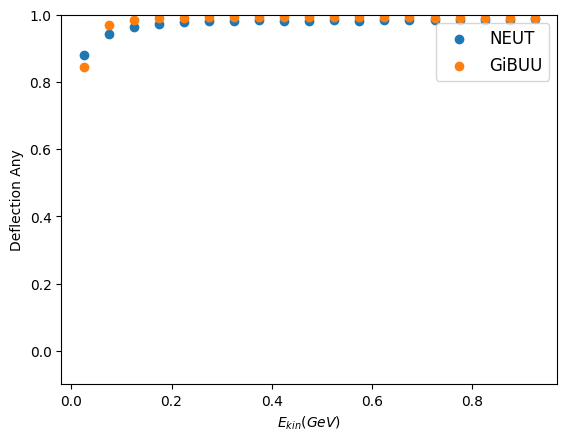

In [78]:
bins_array=np.arange(0.0,1.00,0.05)
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
is_good_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
    # (el_arr<40*np.pi/180) 
)
np_proton_event=ak.sum(is_good_proton, axis=1) > 0

E_evt = E_shift[np_proton_event]
proton_mask_evt = is_good_proton[np_proton_event]
E_sel = E_evt[proton_mask_evt]
pxout_sel=px_arr[np_proton_event][proton_mask_evt]
pyout_sel=py_arr[np_proton_event][proton_mask_evt]
pzout_sel=pz_arr[np_proton_event][proton_mask_evt]
pdg_sel=pdg_arr[np_proton_event][proton_mask_evt]
has_proton = ak.num(E_sel) > 0
E_sel = E_sel[has_proton]
px_sel = pxout_sel[has_proton]
py_sel = pyout_sel[has_proton]
pz_sel = pzout_sel[has_proton]
pdg_sel=pdg_sel[has_proton]

sorted_idx=ak.argsort(E_sel,axis=1,ascending=False)

E_sel=ak.firsts(E_sel[sorted_idx])
px_sel=ak.firsts(px_sel[sorted_idx])
py_sel=ak.firsts(py_sel[sorted_idx])
pz_sel=ak.firsts(pz_sel[sorted_idx])

E_evt = E_primary[np_proton_event]
px_evt= px_arr[:,3][np_proton_event]
py_evt= py_arr[:,3][np_proton_event]
pz_evt= pz_arr[:,3][np_proton_event]

def angout(px_arrx,py_arrx,pz_arrx):
    return np.arctan2(np.sqrt(px_arrx*px_arrx+py_arrx*py_arrx),pz_arrx)

maskp=mode_arr==1
mask_trans=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))>-5*np.pi/180
# maskel=(el_arr>20*np.pi/180) & (el_arr<40*np.pi/180)
mom_trans=np.sqrt(px_evt[mask_trans]*px_evt[mask_trans]+py_evt[mask_trans]*py_evt[mask_trans]+pz_evt[mask_trans]*pz_evt[mask_trans])
hist1,bins1=np.histogram(E_evt[mask_trans],bins=bins_array, range=(0.0,1.5))
hist2,bins2=np.histogram(E_primary[maskp], bins=bins_array,range=(0.,1.5))

binc=(bins1[1:]+bins1[:-1])/2


E_arr3 = E_gibuu_w_med[idx2][:,2:]
ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
E_shift3 = E_arr3 - 0.938
E_primary_gibuu=E_primary
el_arrg=el_arr
is_proton3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 1) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)
# maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
np_proton_event3=ak.sum(is_proton3, axis=1) >= 1
proton_mask_evt3 = is_proton3[np_proton_event3]

# E_evt_gibuu = E_primary_gibuu[np_proton_event3]
E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
has_gibuu_proton = ak.num(E_gibuu_sel) > 0

E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]

sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)

E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])

E_evt3 = E_primary[np_proton_event3]
px_evt3= px_arr[:,3][np_proton_event3]
py_evt3= py_arr[:,3][np_proton_event3]
pz_evt3= pz_arr[:,3][np_proton_event3]

mask_trans_gibuu=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>-5*np.pi/180
mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu]*px_evt3[mask_trans_gibuu]+py_evt3[mask_trans_gibuu]*py_evt3[mask_trans_gibuu]+pz_evt3[mask_trans_gibuu]*pz_evt3[mask_trans_gibuu])

hist11,bins11=np.histogram(E_evt3[mask_trans_gibuu],bins=bins_array,range=(0.0,1.5))


# # E_evt3 = E_shift3[no_pion_evt3 & np_proton_event3]
# # mask_evt3 = is_proton3[no_pion_evt3 & np_proton_event3]

plt.scatter(binc,hist1/hist2, label="NEUT")
plt.ylim(-0.1,1.0)
plt.scatter(binc,hist11/hist2, label="GiBUU")
plt.legend(fontsize=12)
plt.ylabel("Deflection Any")
plt.xlabel(r"$E_{kin}(GeV)$")
# # E_sel3 = E_evt3[mask_evt3]


# # has_proton3 = ak.num(E_sel3) > 0
# # E_sel3 = E_sel3[has_proton3]


# # lead_E_gibuu_w_med_0pi = ak.max(E_sel3, axis=1)

# # plt.hist(
# #     ak.to_numpy(lead_E_gibuu_w_med_0pi),
# #     bins=bins_array,
# #     alpha=1,
# #     histtype="step",
# #     color="red",
# #     label="GIBUU w med"
# # )
print(hist1,hist11,hist2)

In [63]:
pdg_arr[maskp]

<Array [[14, 2112, 13, 2212], ..., [14, ...]] type='3693322 * var * int32'>

## $T_{\pi^+}$

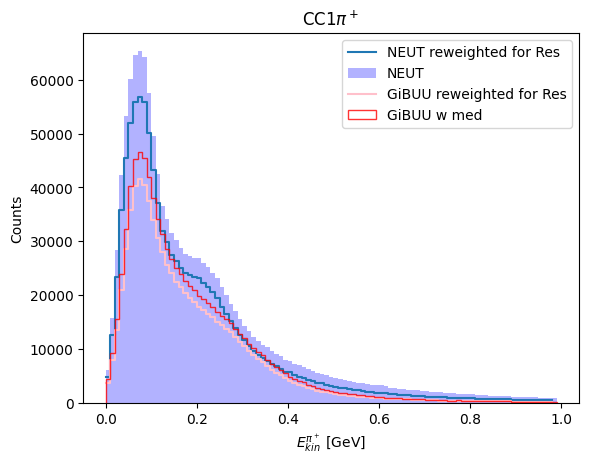

In [ ]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)

# CC1pi+ mask 
mask_cc1pip = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0)
# select only CC1pi+ events
pdg_cc1pip   = pdg_arr[mask_cc1pip]
E_cc1pip     = E_arr[mask_cc1pip]
chase_cc1pip = chase_arr[mask_cc1pip]
mode_cc1pip =  mode_arr[mask_cc1pip]
truenuE_cc1pip= enf_arr[mask_cc1pip]

# pick the pi+ (exactly one per event)
pi_plus_mask = (pdg_cc1pip == 211) & (chase_cc1pip == 1)

E_piplus = E_cc1pip[pi_plus_mask]
mode_piplus=mode_cc1pip[pi_plus_mask]
truenuE_piplus=truenuE_cc1pip[pi_plus_mask]
# flatten (since 1 per event)
E_piplus = ak.flatten(E_piplus)
mode_piplus = ak.flatten(mode_piplus)
truenuE_piplus = ak.flatten(truenuE_piplus)

T_piplus = E_piplus - 0.13957
# kinetic energy


#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum(is_pi0_w_gibuu & final_state_w_gibuu, axis=1)


# CC1pi+ mask 
mask_cc1pip_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0)
# select only CC1pi+ events
pdg_cc1pip_w_gibuu   = pdg_arr3[mask_cc1pip_w_gibuu]
E_cc1pip_w_gibuu     = E_arr3[mask_cc1pip_w_gibuu]
charge_cc1pip_w_gibuu = charge_arrw[mask_cc1pip_w_gibuu]
chase_cc1pip_w_gibuu = chase_arr[mask_cc1pip_w_gibuu]
mode_cc1pip_w_gibuu =  mode_arr3[mask_cc1pip_w_gibuu]
truenuE_piplus_w_gibuu =  enf_arr3[mask_cc1pip_w_gibuu]

# pick the pi+ (exactly one per event)
pi_plus_mask_w_gibuu = (pdg_cc1pip_w_gibuu == 101) & (charge_cc1pip_w_gibuu == 1)

E_piplus_w_gibuu = E_cc1pip_w_gibuu[pi_plus_mask_w_gibuu]
E_piplus_w_gibuu = ak.flatten(E_piplus_w_gibuu)
T_piplus_w_gibuu = E_piplus_w_gibuu - 0.13957

mode_piplus_w_gibuu=mode_cc1pip_w_gibuu[pi_plus_mask_w_gibuu]
truenuE_piplus_w_gibuu=truenuE_piplus_w_gibuu[pi_plus_mask_w_gibuu]
mode_piplus_w_gibuu = ak.flatten(mode_piplus_w_gibuu)
truenuE_piplus_w_gibuu = ak.flatten(truenuE_piplus_w_gibuu)

bins_array = np.arange(0, 1, 0.01)


hist1,bins1=np.histogram(T_piplus[mode_piplus==1], bins=bins_array)
hist2,bins1=np.histogram(T_piplus[mode_piplus==2], bins=bins_array)
hist3,bins1=np.histogram(T_piplus[mode_piplus==26], bins=bins_array)

hist4,bins1=np.histogram(T_piplus[mode_piplus==11], weights=bspl1(truenuE_piplus[mode_piplus==11]), bins=bins_array)
hist5,bins1=np.histogram(T_piplus[mode_piplus==12], weights=bspl2(truenuE_piplus[mode_piplus==12]),bins=bins_array)
hist6,bins1=np.histogram(T_piplus[mode_piplus==13], weights=bspl3(truenuE_piplus[mode_piplus==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")

hist1g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==1], bins=bins_array)
hist2g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==2], bins=bins_array)
hist3g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==26], bins=bins_array)

hist4g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==11], weights=bspl1(truenuE_piplus_w_gibuu[mode_piplus_w_gibuu==11]), bins=bins_array)
hist5g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==12], weights=bspl4(truenuE_piplus_w_gibuu[mode_piplus_w_gibuu==12]),bins=bins_array)
hist6g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==13], weights=bspl4(truenuE_piplus_w_gibuu[mode_piplus_w_gibuu==13]),bins=bins_array)



plt.hist(T_piplus, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")

# plt.hist(T_piplus_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(T_piplus_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$E_{kin}^{\pi^+}$ [GeV]")
plt.ylabel("Counts")
plt.title(r"CC1$\pi^+$")
plt.legend()

## $T_{\pi_0}$

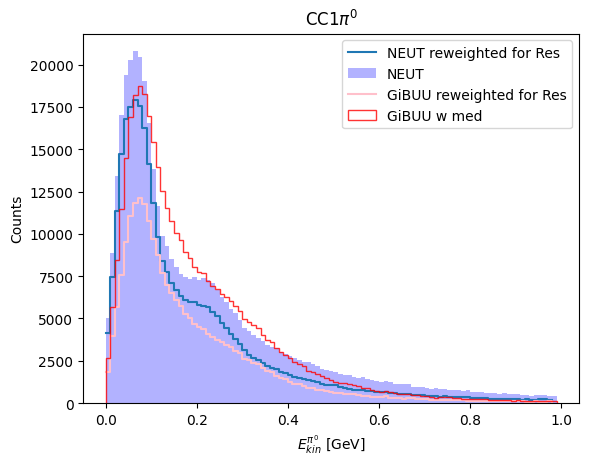

In [ ]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)

# CC1pi+ mask 
mask_cc1pip = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0)
mask_cc1pi0 = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 1)

# select only CC1pi+ events
pdg_cc1pi0   = pdg_arr[mask_cc1pi0]
E_cc1pi0     = E_arr[mask_cc1pi0]
chase_cc1pi0 = chase_arr[mask_cc1pi0]
mode_cc1pi0 =  mode_arr[mask_cc1pi0]
truenuE_cc1pi0= enf_arr[mask_cc1pi0]

# pick the pi+ (exactly one per event)
pi_zero_mask = (pdg_cc1pi0 == 111) & (chase_cc1pi0 == 1)

E_pi0 = E_cc1pi0[pi_zero_mask]
mode_pi0=mode_cc1pi0[pi_zero_mask]
truenuE_pi0=truenuE_cc1pi0[pi_zero_mask]
# flatten (since 1 per event)
E_pi0 = ak.flatten(E_pi0)
mode_pizero = ak.flatten(mode_pi0)
truenuE_pizero = ak.flatten(truenuE_pi0)

T_pizero = E_pi0 - 0.13957
# kinetic energy


#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum(is_pi0_w_gibuu & final_state_w_gibuu, axis=1)


# CC1pi+ mask 
mask_cc1pip_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0)
mask_cc1pi0_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 1)

# select only CC1pi+ events
pdg_cc1pi0_w_gibuu   = pdg_arr3[mask_cc1pi0_w_gibuu]
E_cc1pi0_w_gibuu     = E_arr3[mask_cc1pi0_w_gibuu]
charge_cc1pi0_w_gibuu = charge_arrw[mask_cc1pi0_w_gibuu]
chase_cc1pi0_w_gibuu = chase_arr[mask_cc1pi0_w_gibuu]
mode_cc1pi0_w_gibuu =  mode_arr3[mask_cc1pi0_w_gibuu]
truenuE_pizero_w_gibuu =  enf_arr3[mask_cc1pi0_w_gibuu]

# pick the pi+ (exactly one per event)
pi_zero_mask_w_gibuu = (pdg_cc1pi0_w_gibuu == 101) & (charge_cc1pi0_w_gibuu == 0)

E_pizero_w_gibuu = E_cc1pi0_w_gibuu[pi_zero_mask_w_gibuu]
E_pizero_w_gibuu = ak.flatten(E_pizero_w_gibuu)
T_pizero_w_gibuu = E_pizero_w_gibuu - 0.13957

mode_pizero_w_gibuu=mode_cc1pi0_w_gibuu[pi_zero_mask_w_gibuu]
truenuE_pizero_w_gibuu=truenuE_pizero_w_gibuu[pi_zero_mask_w_gibuu]
mode_pizero_w_gibuu = ak.flatten(mode_pizero_w_gibuu)
truenuE_pizero_w_gibuu = ak.flatten(truenuE_pizero_w_gibuu)

bins_array = np.arange(0, 1, 0.01)


hist1,bins1=np.histogram(T_pizero[mode_pizero==1], bins=bins_array)
hist2,bins1=np.histogram(T_pizero[mode_pizero==2], bins=bins_array)
hist3,bins1=np.histogram(T_piplus[mode_pizero==26], bins=bins_array)

hist4,bins1=np.histogram(T_pizero[mode_pizero==11], weights=bspl1(truenuE_pizero[mode_pizero==11]), bins=bins_array)
hist5,bins1=np.histogram(T_pizero[mode_pizero==12], weights=bspl2(truenuE_pizero[mode_pizero==12]),bins=bins_array)
hist6,bins1=np.histogram(T_pizero[mode_pizero==13], weights=bspl3(truenuE_pizero[mode_pizero==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")

hist1g,bins1=np.histogram(T_pizero_w_gibuu[mode_pizero_w_gibuu==1], bins=bins_array)
hist2g,bins1=np.histogram(T_pizero_w_gibuu[mode_pizero_w_gibuu==2], bins=bins_array)
hist3g,bins1=np.histogram(T_pizero_w_gibuu[mode_pizero_w_gibuu==26], bins=bins_array)

hist4g,bins1=np.histogram(T_pizero_w_gibuu[mode_pizero_w_gibuu==11], weights=bspl1(truenuE_pizero_w_gibuu[mode_pizero_w_gibuu==11]), bins=bins_array)
hist5g,bins1=np.histogram(T_pizero_w_gibuu[mode_pizero_w_gibuu==12], weights=bspl4(truenuE_pizero_w_gibuu[mode_pizero_w_gibuu==12]),bins=bins_array)
hist6g,bins1=np.histogram(T_pizero_w_gibuu[mode_pizero_w_gibuu==13], weights=bspl4(truenuE_pizero_w_gibuu[mode_pizero_w_gibuu==13]),bins=bins_array)



plt.hist(T_pizero, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")

# plt.hist(T_piplus_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(T_pizero_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$E_{kin}^{\pi^0}$ [GeV]")
plt.ylabel("Counts")
plt.title(r"CC1$\pi^0$")
plt.legend()

## $Q^2$

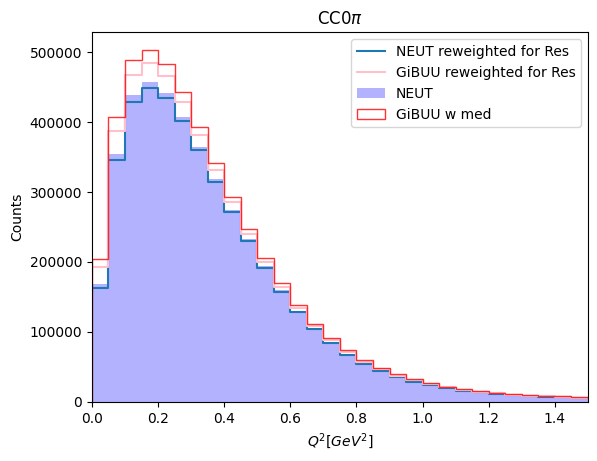

In [ ]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
# proton selection (final state)

mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212)|(pdg_arr == 2112))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton > 0)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
Q2_cc0pi_neut = Q2_arr[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)|(charge_arrw == 0)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>0)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
Q2_cc0pi_w_gibuu = Q2_arr[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==1], bins=bins_array)
hist2,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==2], bins=bins_array)
hist3,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==26], bins=bins_array)

hist4,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==11], weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==12], weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==13], weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1], bins=bins_array)
hist2g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2], bins=bins_array)
hist3g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26], bins=bins_array)

a=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(a, weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(b, weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(c, weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(Q2_cc0pi_neut, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(Q2_cc0pi_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$Q^2 [GeV^2]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC0$\pi$")
plt.legend()

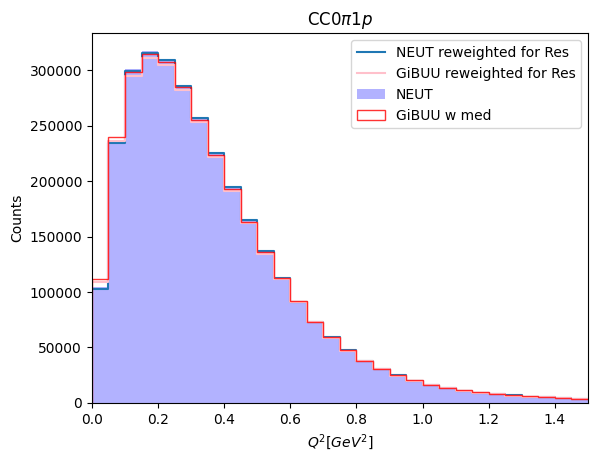

In [ ]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
# proton selection (final state)

mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton ==1)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
Q2_cc0pi_neut = Q2_arr[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu==1)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
Q2_cc0pi_w_gibuu = Q2_arr[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==1], bins=bins_array)
hist2,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==2], bins=bins_array)
hist3,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==26], bins=bins_array)

hist4,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==11], weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==12], weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==13], weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1], bins=bins_array)
hist2g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2], bins=bins_array)
hist3g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26], bins=bins_array)

a=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(a, weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(b, weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(c, weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(Q2_cc0pi_neut, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(Q2_cc0pi_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$Q^2 [GeV^2]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC0$\pi1p$")
plt.legend()

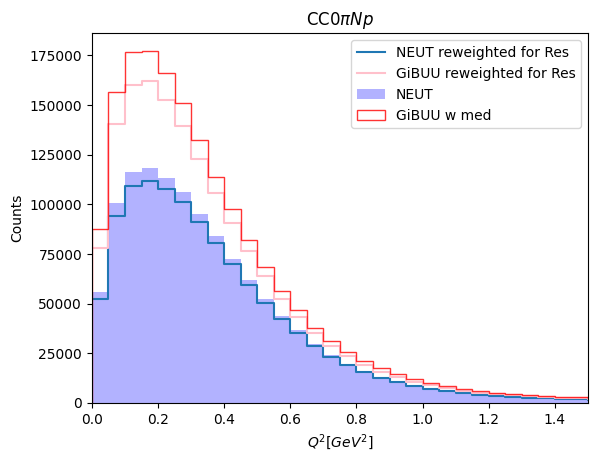

In [ ]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
# proton selection (final state)

mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton > 1)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
Q2_cc0pi_neut = Q2_arr[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>1)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
Q2_cc0pi_w_gibuu = Q2_arr[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==1], bins=bins_array)
hist2,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==2], bins=bins_array)
hist3,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==26], bins=bins_array)

hist4,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==11], weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==12], weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==13], weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1], bins=bins_array)
hist2g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2], bins=bins_array)
hist3g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26], bins=bins_array)

a=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(a, weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(b, weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(c, weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(Q2_cc0pi_neut, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(Q2_cc0pi_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$Q^2 [GeV^2]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC0$\pi Np$")
plt.legend()

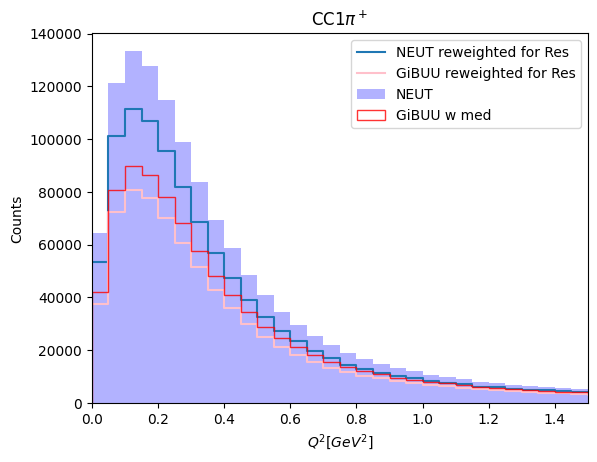

In [ ]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
# proton selection (final state)

mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212)|(pdg_arr == 2112))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton > 0)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
Q2_cc0pi_neut = Q2_arr[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)|(charge_arrw == 0)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>0)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
Q2_cc0pi_w_gibuu = Q2_arr[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==1], bins=bins_array)
hist2,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==2], bins=bins_array)
hist3,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==26], bins=bins_array)

hist4,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==11], weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==12], weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(Q2_cc0pi_neut[mode_cc0pi_neut==13], weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1], bins=bins_array)
hist2g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2], bins=bins_array)
hist3g,bins1=np.histogram(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26], bins=bins_array)

a=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(a, weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(b, weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(c, weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(Q2_cc0pi_neut, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(Q2_cc0pi_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$Q^2 [GeV^2]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC1$\pi^+$")
plt.legend()

## $p_\mu$

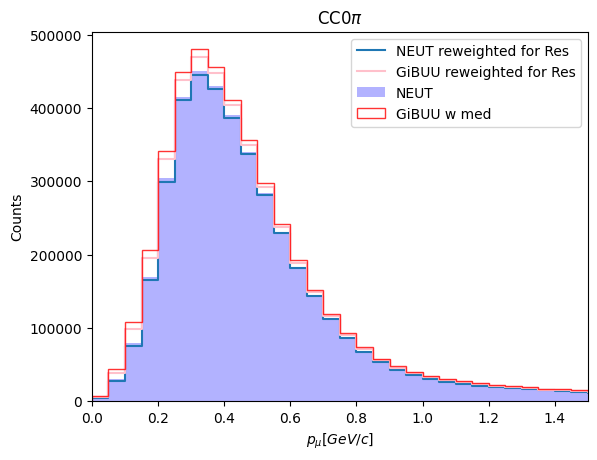

In [13]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
flesp_index_arr=flesp_index[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
px_arr   = px[idx1]
py_arr = py[idx1]
pz_arr   = pz[idx1]
p_arr=px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr
# proton selection (final state)
row_idx = ak.local_index(E_arr, axis=0)
out_plepton_squared = p_arr[row_idx, flesp_index_arr]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212)|(pdg_arr == 2112))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton > 0)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
out_plepton_squared_cc0pi_neut = out_plepton_squared[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
out_plepton_squared_gibuu=px_gibuu_w_med[idx2][:,0]*px_gibuu_w_med[idx2][:,0]+py_gibuu_w_med[idx2][:,0]*py_gibuu_w_med[idx2][:,0]+pz_gibuu_w_med[idx2][:,0]*pz_gibuu_w_med[idx2][:,0]


mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)|(charge_arrw == 0)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>0)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
out_plepton_squared_gibuu_cc0pi_w_gibuu = out_plepton_squared_gibuu[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==1]), bins=bins_array)
hist2,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==2]), bins=bins_array)
hist3,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==26]), bins=bins_array)

hist4,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==11]), weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==12]), weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==13]), weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1]), bins=bins_array)
hist2g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2]), bins=bins_array)
hist3g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26]), bins=bins_array)

a=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(np.sqrt(a), weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(np.sqrt(b), weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(np.sqrt(c), weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(np.sqrt(out_plepton_squared_cc0pi_neut), bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu), bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$p_\mu [GeV/c]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC0$\pi$")
plt.legend()

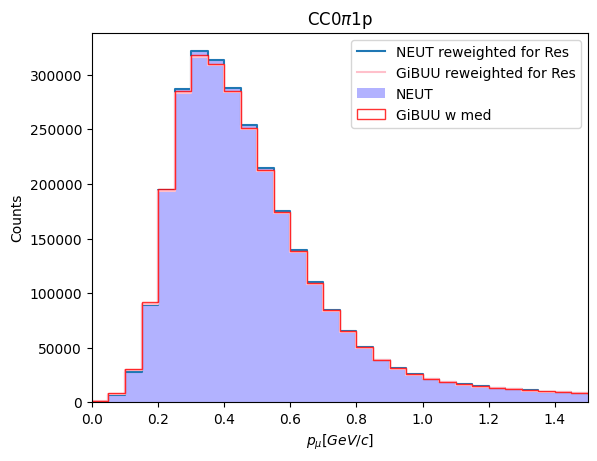

In [14]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
flesp_index_arr=flesp_index[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
px_arr   = px[idx1]
py_arr = py[idx1]
pz_arr   = pz[idx1]
p_arr=px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr
# proton selection (final state)
row_idx = ak.local_index(E_arr, axis=0)
out_plepton_squared = p_arr[row_idx, flesp_index_arr]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton ==1)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
out_plepton_squared_cc0pi_neut = out_plepton_squared[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
out_plepton_squared_gibuu=px_gibuu_w_med[idx2][:,0]*px_gibuu_w_med[idx2][:,0]+py_gibuu_w_med[idx2][:,0]*py_gibuu_w_med[idx2][:,0]+pz_gibuu_w_med[idx2][:,0]*pz_gibuu_w_med[idx2][:,0]


mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu==1)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
out_plepton_squared_gibuu_cc0pi_w_gibuu = out_plepton_squared_gibuu[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==1]), bins=bins_array)
hist2,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==2]), bins=bins_array)
hist3,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==26]), bins=bins_array)

hist4,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==11]), weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==12]), weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==13]), weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1]), bins=bins_array)
hist2g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2]), bins=bins_array)
hist3g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26]), bins=bins_array)

a=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(np.sqrt(a), weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(np.sqrt(b), weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(np.sqrt(c), weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(np.sqrt(out_plepton_squared_cc0pi_neut), bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu), bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$p_\mu [GeV/c]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC0$\pi$1p")
plt.legend()

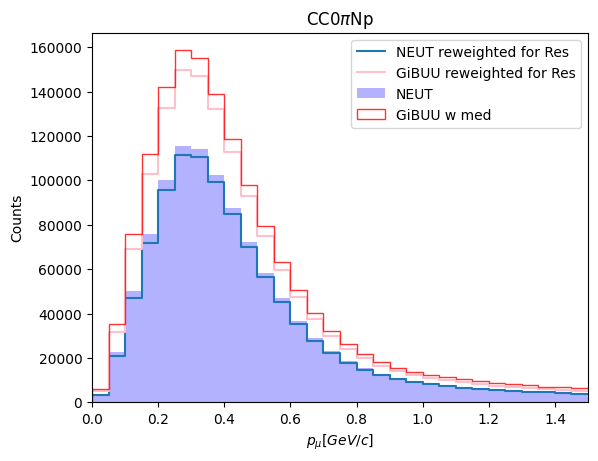

In [15]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
flesp_index_arr=flesp_index[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
px_arr   = px[idx1]
py_arr = py[idx1]
pz_arr   = pz[idx1]
p_arr=px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr
# proton selection (final state)
row_idx = ak.local_index(E_arr, axis=0)
out_plepton_squared = p_arr[row_idx, flesp_index_arr]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton >1)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
out_plepton_squared_cc0pi_neut = out_plepton_squared[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
out_plepton_squared_gibuu=px_gibuu_w_med[idx2][:,0]*px_gibuu_w_med[idx2][:,0]+py_gibuu_w_med[idx2][:,0]*py_gibuu_w_med[idx2][:,0]+pz_gibuu_w_med[idx2][:,0]*pz_gibuu_w_med[idx2][:,0]


mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>1)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
out_plepton_squared_gibuu_cc0pi_w_gibuu = out_plepton_squared_gibuu[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==1]), bins=bins_array)
hist2,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==2]), bins=bins_array)
hist3,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==26]), bins=bins_array)

hist4,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==11]), weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==12]), weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==13]), weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1]), bins=bins_array)
hist2g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2]), bins=bins_array)
hist3g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26]), bins=bins_array)

a=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(np.sqrt(a), weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(np.sqrt(b), weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(np.sqrt(c), weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(np.sqrt(out_plepton_squared_cc0pi_neut), bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu), bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$p_\mu [GeV/c]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC0$\pi$Np")
plt.legend()

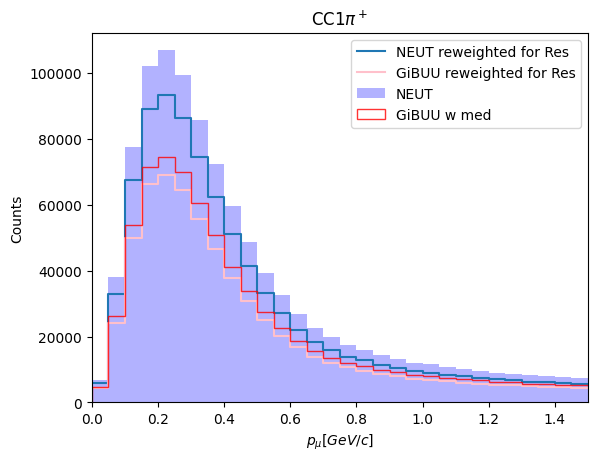

In [16]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
flesp_index_arr=flesp_index[idx1]
mass_offset=0.035
Ef = E_arr - 0.938 - mass_offset
px_arr   = px[idx1]
py_arr = py[idx1]
pz_arr   = pz[idx1]
p_arr=px_arr*px_arr+py_arr*py_arr+pz_arr*pz_arr
# proton selection (final state)
row_idx = ak.local_index(E_arr, axis=0)
out_plepton_squared = p_arr[row_idx, flesp_index_arr]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 1)

# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_proton = ((pdg_arr == 2212)|(pdg_arr == 2112))  & (Ef > 0)

# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
n_proton = ak.sum(is_proton & final_state, axis=1)

# CC1pi+ mask 
mask_cc0pi = (n_pi_plus == 1) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton > 0)
# select only CC1pi+ events
pdg_cc0pi  = pdg_arr[mask_cc0pi]
E_cc0pi     = E_arr[mask_cc0pi]
chase_cc0pi = chase_arr[mask_cc0pi]
out_plepton_squared_cc0pi_neut = out_plepton_squared[mask_cc0pi]
mode_cc0pi_neut=mode_arr[mask_cc0pi]
enf_cc0pi_neut=enf_arr[mask_cc0pi]
mode_cc0pi_neut=ak.firsts(mode_arr[mask_cc0pi])
enf_cc0pi_neut=ak.firsts(enf_arr[mask_cc0pi])
#################### GiBUU w med
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arrw = charge_gibuu_w_med[idx2][:,2:]
E_arr3     = E_gibuu_w_med[idx2][:,2:]
out_plepton_squared_gibuu=px_gibuu_w_med[idx2][:,0]*px_gibuu_w_med[idx2][:,0]+py_gibuu_w_med[idx2][:,0]*py_gibuu_w_med[idx2][:,0]+pz_gibuu_w_med[idx2][:,0]*pz_gibuu_w_med[idx2][:,0]


mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
Ef_gibuu = E_arr3 - 0.938 

# final state
final_state_w_gibuu = (pdg_arr3 == 101)

# pion definitions
is_pi_plus_w_gibuu  = (charge_arrw == 1)
is_pi_minus_w_gibuu = (charge_arrw == -1)
is_pi0_w_gibuu      = (charge_arrw == 0)
is_proton_w_gibuu = ((charge_arrw == 1)|(charge_arrw == 0)) & (pdg_arr3 == 1) & (Ef_gibuu > 0)

# counts per event
n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
n_proton_w_gibuu      = ak.sum((is_proton_w_gibuu), axis=1)


# CC1pi+ mask 
mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>0)
# select only CC1pi+ events
pdg_cc0pi_w_gibuu   = pdg_arr3[mask_cc0pi_w_gibuu]
E_cc0pi_w_gibuu     = E_arr3[mask_cc0pi_w_gibuu]
charge_cc0pi_w_gibuu = charge_arrw[mask_cc0pi_w_gibuu]
out_plepton_squared_gibuu_cc0pi_w_gibuu = out_plepton_squared_gibuu[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = mode_arr3[mask_cc0pi_w_gibuu]
enf_cc0pi_w_gibuu = enf_arr3[mask_cc0pi_w_gibuu]
mode_cc0pi_w_gibuu = ak.firsts(mode_cc0pi_w_gibuu)
enf_cc0pi_w_gibuu = ak.firsts(enf_cc0pi_w_gibuu)
# pick the pi+ (exactly one per event)

bins_array = np.arange(0, 3, 0.05)

hist1,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==1]), bins=bins_array)
hist2,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==2]), bins=bins_array)
hist3,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==26]), bins=bins_array)

hist4,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==11]), weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut==11]), bins=bins_array)
hist5,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==12]), weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut==12]),bins=bins_array)
hist6,bins1=np.histogram(np.sqrt(out_plepton_squared_cc0pi_neut[mode_cc0pi_neut==13]), weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")


hist1g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==1]), bins=bins_array)
hist2g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==2]), bins=bins_array)
hist3g,bins1=np.histogram(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==26]), bins=bins_array)

a=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
b=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
c=out_plepton_squared_gibuu_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
aa=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]
bb=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==12]
cc=enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==13]
hist4g,bins1=np.histogram(np.sqrt(a), weights=bspl1(aa), bins=bins_array)
hist5g,bins1=np.histogram(np.sqrt(b), weights=bspl4(bb),bins=bins_array)
hist6g,bins1=np.histogram(np.sqrt(c), weights=bspl4(cc),bins=bins_array)
plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")


plt.hist(np.sqrt(out_plepton_squared_cc0pi_neut), bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.hist(Q2_cc0pi_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
plt.hist(np.sqrt(out_plepton_squared_gibuu_cc0pi_w_gibuu), bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$p_\mu [GeV/c]$")
plt.xlim(0,1.5)
plt.ylabel("Counts")
plt.title(r"CC1$\pi^+$")
plt.legend()

In [79]:
np.unique(aa)

<Array [0.317, 0.321, 0.327, ..., 18.8, 19, 19.6] type='506886 * ?float64'>

In [69]:
np.unique(Q2_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11]),np.unique(enf_cc0pi_w_gibuu[mode_cc0pi_w_gibuu==11])

(<Array [0.000511, 0.000597, 0.000769, ..., 9.24, None] type='518911 * ?float64'>,
 <Array [0.317, 0.321, 0.327, ..., 19, 19.6, None] type='507252 * ?float64'>)

In [89]:
len(ID_gibuu_w_med[idx2][mask_cc0pi_gibuu])

4831272

In [90]:
len(mode_neut[mask_cc0pi_gibuu])

4831272

## Test

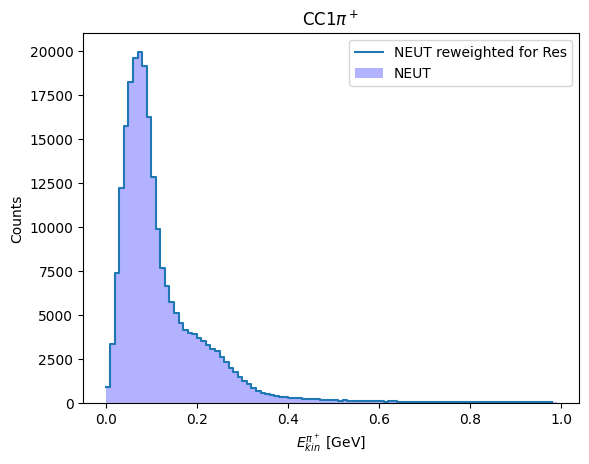

In [21]:
pdg_arr   = pdg[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
mode_arr=mode[idx1]*ak.ones_like(pdg[idx1])
enf_arr=truenuE[idx1]*ak.ones_like(pdg[idx1])
# final state
final_state = (chase_arr == 0)
# pion definitions
is_pi_plus  = (pdg_arr == 211)
is_pi_minus = (pdg_arr == -211)
is_pi0      = (pdg_arr == 111)
is_mode11= (mode_arr==11)
# counts per event
n_pi_plus  = ak.sum(is_pi_plus & final_state & is_mode11 , axis=1)
n_pi_minus = ak.sum(is_pi_minus & final_state & is_mode11, axis=1)
n_pi0      = ak.sum(is_pi0 & final_state & is_mode11, axis=1)

# CC1pi+ mask 
mask_cc1pip = (n_pi_plus > 0) & (n_pi_minus == 0) & (n_pi0 == 0)
# select only CC1pi+ events
pdg_cc1pip   = pdg_arr[mask_cc1pip]
E_cc1pip     = E_arr[mask_cc1pip]
chase_cc1pip = chase_arr[mask_cc1pip]
mode_cc1pip =  mode_arr[mask_cc1pip]
truenuE_cc1pip= enf_arr[mask_cc1pip]

# pick the pi+ (exactly one per event)
pi_plus_mask = (pdg_cc1pip == 211) & (chase_cc1pip == 1)

E_piplus = E_cc1pip[pi_plus_mask]
mode_piplus=mode_cc1pip[pi_plus_mask]
truenuE_piplus=truenuE_cc1pip[pi_plus_mask]
# flatten (since 1 per event)
E_piplus = ak.flatten(E_piplus)
mode_piplus = ak.flatten(mode_piplus)
truenuE_piplus = ak.flatten(truenuE_piplus)

T_piplus = E_piplus - 0.13957
# kinetic energy
# #################### GiBUU w med
# pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
# charge_arrw = charge_gibuu_w_med[idx2][:,2:]
# E_arr3     = E_gibuu_w_med[idx2][:,2:]
# mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
# enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
# # final state
# final_state_w_gibuu = (pdg_arr3 == 101)

# # pion definitions
# is_pi_plus_w_gibuu  = (charge_arrw == 1)
# is_pi_minus_w_gibuu = (charge_arrw == -1)
# is_pi0_w_gibuu      = (charge_arrw == 0)

# # counts per event
# n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
# n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
# n_pi0_w_gibuu      = ak.sum(is_pi0_w_gibuu & final_state_w_gibuu, axis=1)


# # CC1pi+ mask 
# mask_cc1pip_w_gibuu = (n_pi_plus_w_gibuu == 1) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0)
# # select only CC1pi+ events
# pdg_cc1pip_w_gibuu   = pdg_arr3[mask_cc1pip_w_gibuu]
# E_cc1pip_w_gibuu     = E_arr3[mask_cc1pip_w_gibuu]
# charge_cc1pip_w_gibuu = charge_arrw[mask_cc1pip_w_gibuu]
# chase_cc1pip_w_gibuu = chase_arr[mask_cc1pip_w_gibuu]
# mode_cc1pip_w_gibuu =  mode_arr3[mask_cc1pip_w_gibuu]
# truenuE_piplus_w_gibuu =  enf_arr3[mask_cc1pip_w_gibuu]

# # pick the pi+ (exactly one per event)
# pi_plus_mask_w_gibuu = (pdg_cc1pip_w_gibuu == 101) & (charge_cc1pip_w_gibuu == 1)

# E_piplus_w_gibuu = E_cc1pip_w_gibuu[pi_plus_mask_w_gibuu]
# E_piplus_w_gibuu = ak.flatten(E_piplus_w_gibuu)
# T_piplus_w_gibuu = E_piplus_w_gibuu - 0.13957

# mode_piplus_w_gibuu=mode_cc1pip_w_gibuu[pi_plus_mask_w_gibuu]
# truenuE_piplus_w_gibuu=truenuE_piplus_w_gibuu[pi_plus_mask_w_gibuu]
# mode_piplus_w_gibuu = ak.flatten(mode_piplus_w_gibuu)
# truenuE_piplus_w_gibuu = ak.flatten(truenuE_piplus_w_gibuu)

bins_array = np.arange(0, 1, 0.01)


hist1,bins1=np.histogram(T_piplus[mode_piplus==1], bins=bins_array)
hist2,bins1=np.histogram(T_piplus[mode_piplus==2], bins=bins_array)
hist3,bins1=np.histogram(T_piplus[mode_piplus==26], bins=bins_array)

hist4,bins1=np.histogram(T_piplus[mode_piplus==11], weights=bspl1(truenuE_piplus[mode_piplus==11]), bins=bins_array)
hist5,bins1=np.histogram(T_piplus[mode_piplus==12], weights=bspl2(truenuE_piplus[mode_piplus==12]),bins=bins_array)
hist6,bins1=np.histogram(T_piplus[mode_piplus==13], weights=bspl3(truenuE_piplus[mode_piplus==13]),bins=bins_array)

plt.step(bins1[:-1],hist1+hist2+hist3+hist4+hist5+hist6, where="post",  label="NEUT reweighted for Res")

# hist1g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==1], bins=bins_array)
# hist2g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==2], bins=bins_array)
# hist3g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==26], bins=bins_array)

# hist4g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==11], weights=bspl1(truenuE_piplus_w_gibuu[mode_piplus_w_gibuu==11]), bins=bins_array)
# hist5g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==12], weights=bspl4(truenuE_piplus_w_gibuu[mode_piplus_w_gibuu==12]),bins=bins_array)
# hist6g,bins1=np.histogram(T_piplus_w_gibuu[mode_piplus_w_gibuu==13], weights=bspl4(truenuE_piplus_w_gibuu[mode_piplus_w_gibuu==13]),bins=bins_array)



plt.hist(T_piplus, bins=bins_array, color="blue", alpha=0.3, label="NEUT")
# plt.step(bins1[:-1],hist1g+hist2g+hist3g+hist4g+hist5g+hist6g, color="pink", where="post",  label="GiBUU reweighted for Res")

# plt.hist(T_piplus_wo_gibuu, bins=bins_array, color="blue", histtype="step", alpha=0.8, label="GiBUU w/o med")
# plt.hist(T_piplus_w_gibuu, bins=bins_array, color="red", histtype="step", alpha=0.8, label="GiBUU w med")

plt.xlabel(r"$E_{kin}^{\pi^+}$ [GeV]")
plt.ylabel("Counts")
plt.title(r"CC1$\pi^+$")
plt.legend()

## some extra checks for proton transparency

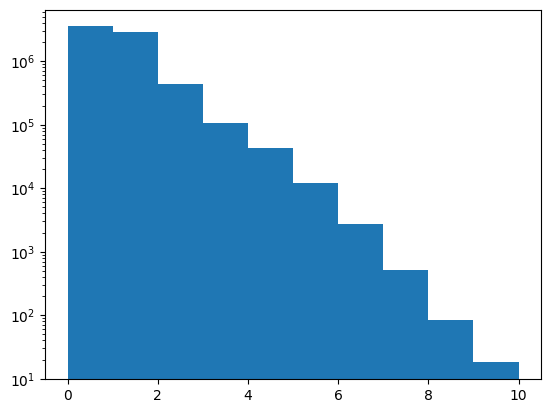

In [ ]:
hist=history_gibuu_w_med[:,2:][idx2]

mask=(hist==0)
plt.hist(ak.num(hist[mask]))
plt.yscale("log")

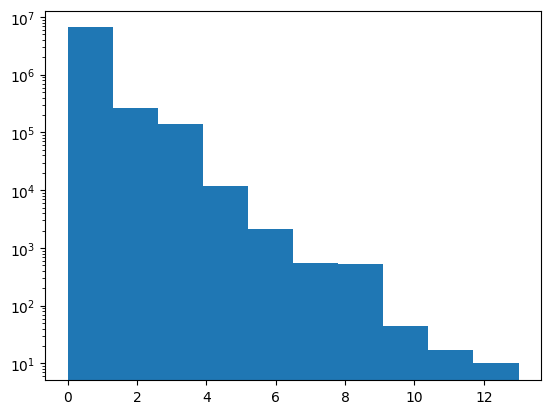

In [17]:
hist=history_gibuu_w_med[:,2:][idx2]
mask=(hist<0)
plt.hist(ak.num(hist[mask]))
plt.yscale("log")

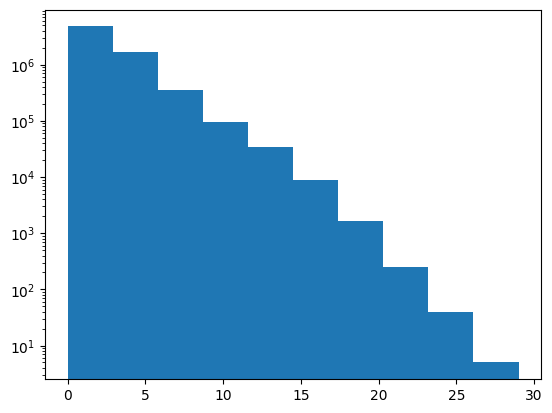

In [18]:
hist=history_gibuu_w_med[:,2:][idx2]
mask=(hist>0)
plt.hist(ak.num(hist[mask]))
plt.yscale("log")

In [24]:
hist=history_gibuu_w_med[:,2:][idx2]
mask=(hist==0)
mask=(hist>0)
mask=(hist<0)

hist1,bin1=np.histogram(ak.num(hist[mask]),bins=np.arange(0,10,1))
hist2,bin2=np.histogram(ak.num(hist),bins=np.arange(0,10,1))
hist1/hist2

<Array [1.61e+05, 0.0537, 0.143, ..., 0.00375, 0.00341] type='9 * float64'>

[4.22e+05, 4.33e+05, 3.8e+05, 3.08e+05, 2.35e+05, ..., 1.02e+03, 896, 796, 693] [3.89e+05, 4.19e+05, 3.82e+05, 3.16e+05, 2.42e+05, ..., 1.04e+03, 899, 775, 699] [5.77e+05, 6.63e+05, 6e+05, 4.88e+05, ..., 1.78e+03, 1.54e+03, 1.33e+03]


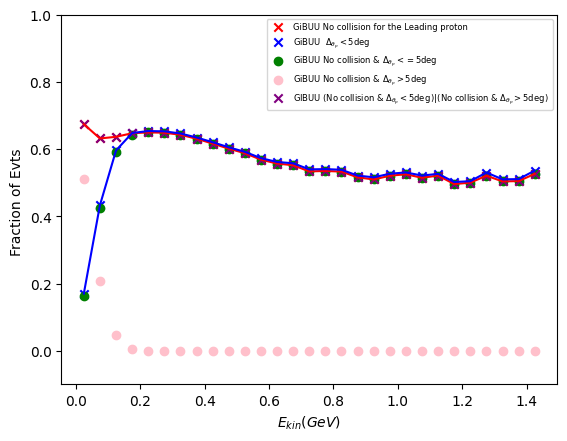

In [61]:
bins_array=np.arange(0.0,1.50,0.05)
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
is_good_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 1) &
    (E_shift > 0.0) 
    # (el_arr>20*np.pi/180) & 
    # (el_arr<40*np.pi/180) 
)
is_bad_proton = ( (mode_arr==1) &
    (pdg_arr == 2212) &
    (chase_arr == 0)

)
np_proton_event=ak.sum(is_good_proton, axis=1) > 0

E_evt = E_shift[np_proton_event]
proton_mask_evt = is_good_proton[np_proton_event]
E_sel = E_evt[proton_mask_evt]
pxout_sel=px_arr[np_proton_event][proton_mask_evt]
pyout_sel=py_arr[np_proton_event][proton_mask_evt]
pzout_sel=pz_arr[np_proton_event][proton_mask_evt]
pdg_sel=pdg_arr[np_proton_event][proton_mask_evt]
has_proton = ak.num(E_sel) > 0
E_sel = E_sel[has_proton]
px_sel = pxout_sel[has_proton]
py_sel = pyout_sel[has_proton]
pz_sel = pzout_sel[has_proton]
pdg_sel=pdg_sel[has_proton]
proton_mask_evt = is_good_proton[np_proton_event]
proton_mask_evt2 = is_bad_proton[np_proton_event]
chase_evt2=chase_arr[np_proton_event][proton_mask_evt]
chase_evt3=chase_arr[np_proton_event][proton_mask_evt2]
sorted_idx=ak.argsort(E_sel,axis=1,ascending=False)

E_sel=ak.firsts(E_sel[sorted_idx])
px_sel=ak.firsts(px_sel[sorted_idx])
py_sel=ak.firsts(py_sel[sorted_idx])
pz_sel=ak.firsts(pz_sel[sorted_idx])

E_evt = E_primary[np_proton_event]
px_evt= px_arr[:,3][np_proton_event]
py_evt= py_arr[:,3][np_proton_event]
pz_evt= pz_arr[:,3][np_proton_event]

def angout(px_arrx,py_arrx,pz_arrx):
    return np.arctan2(np.sqrt(px_arrx*px_arrx+py_arrx*py_arrx),pz_arrx)

maskp=mode_arr==1
# mask_trans=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=5*np.pi/180
# mask_trans2=ak.num(chase_evt2)==1
# mask_trans3=ak.num(chase_evt3)==0
# # maskel=(el_arr>20*np.pi/180) & (el_arr<40*np.pi/180)
# mom_trans=np.sqrt(px_evt[mask_trans&mask_trans2&mask_trans3]*px_evt[mask_trans&mask_trans2&mask_trans3]+py_evt[mask_trans&mask_trans2&mask_trans3]*py_evt[mask_trans&mask_trans2&mask_trans3]+pz_evt[mask_trans&mask_trans2&mask_trans3]*pz_evt[mask_trans&mask_trans2&mask_trans3])
# hist1,bins1=np.histogram(E_evt[mask_trans&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))
hist2,bins2=np.histogram(E_primary[maskp], bins=bins_array,range=(0.,1.5))

# mask_trans4=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=10*np.pi/180
# mask_trans5=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=15*np.pi/180
# mask_trans6=abs(angout(px_evt,py_evt,pz_evt)-angout(px_sel,py_sel,pz_sel))<=20*np.pi/180

# hist3,bins1=np.histogram(E_evt[mask_trans4&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))
# hist4,bins1=np.histogram(E_evt[mask_trans5&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))
# hist5,bins1=np.histogram(E_evt[mask_trans6&mask_trans2&mask_trans3],bins=bins_array, range=(0.0,1.5))



binc=(bins2[1:]+bins2[:-1])/2


E_arr3 = E_gibuu_w_med[idx2][:,2:]
ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
history_gibuu_arr3=history_gibuu_w_med[idx2][:,2:]

px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
E_shift3 = E_arr3 - 0.938
E_primary_gibuu=E_primary
el_arrg=el_arr
is_proton3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 1) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)

is_neutron3 = ( (prod_id_arr3==1) &
    (ID_arr3 == 1) &
    (charge_arr3 == 0) &
    (E_shift3 > 0.0)  
    # (el_arrg>20*np.pi/180) & 
    # (el_arrg<40*np.pi/180) &
    # (ang_out_g>0*np.pi/180) & 
    # (ang_out_g<90*np.pi/180) 
)
# maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
np_proton_event3=ak.sum(is_proton3, axis=1) == 1
proton_mask_evt3 = is_proton3[np_proton_event3]
neutron_mask_evt3 = is_neutron3[np_proton_event3]

# E_evt_gibuu = E_primary_gibuu[np_proton_event3]
E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
has_gibuu_proton = ak.num(E_gibuu_sel) > 0
has_gibuu_neutron = ak.num(E_shift3[np_proton_event3][neutron_mask_evt3]) > 0
history_gibuu_sel=history_gibuu_arr3[np_proton_event3][proton_mask_evt3]


E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]
history_gibuu_sel=history_gibuu_sel[has_gibuu_proton]

sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)

E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])
history_gibuu_sel=ak.firsts(history_gibuu_sel[sorted_gibuu_idx])

E_evt3 = E_primary[np_proton_event3]
px_evt3= px_arr[:,3][np_proton_event3]
py_evt3= py_arr[:,3][np_proton_event3]
pz_evt3= pz_arr[:,3][np_proton_event3]

mask_trans_gibuu2=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=5*np.pi/180
mask_trans_gibuu_neutron=has_gibuu_neutron==0
mask_trans_gibuu=history_gibuu_sel==0
mask_trans_gibuu3=(abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=5*np.pi/180) & (history_gibuu_sel==0)
mask_trans_gibuu4=(abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))>5*np.pi/180) & (history_gibuu_sel==0)

# mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu]*px_evt3[mask_trans_gibuu]+py_evt3[mask_trans_gibuu]*py_evt3[mask_trans_gibuu]+pz_evt3[mask_trans_gibuu]*pz_evt3[mask_trans_gibuu])

hist11,bins11=np.histogram(E_evt3[mask_trans_gibuu & mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))


# mask_trans_gibuu2=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=10*np.pi/180
# mask_trans_gibuu3=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=15*np.pi/180
# mask_trans_gibuu4=abs(angout(px_evt3,py_evt3,pz_evt3)-angout(px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel))<=20*np.pi/180

hist22,bins11=np.histogram(E_evt3[mask_trans_gibuu2 &  mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
hist33,bins11=np.histogram(E_evt3[mask_trans_gibuu3 & mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
hist44,bins11=np.histogram(E_evt3[mask_trans_gibuu4 & mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))


# # E_evt3 = E_shift3[no_pion_evt3 & np_proton_event3]
# # mask_evt3 = is_proton3[no_pion_evt3 & np_proton_event3]

# plt.scatter(binc,hist1/hist2,color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}<5\deg$")
# plt.scatter(binc,hist3/hist2,color="green",marker="o", label=r"NEUT $\Delta_{\theta_p}<10\deg$")
# plt.scatter(binc,hist4/hist2,color="blue",marker="o", label=r"NEUT $\Delta_{\theta_p}<15\deg$")
# plt.scatter(binc,hist5/hist2,color="pink",marker="o", label=r"NEUT $\Delta_{\theta_p}<20\deg$")
# plt.plot(binc,hist5/hist2,color="grey")

plt.ylim(-0.1,1.0)
plt.scatter(binc,hist11/hist2, color="red",marker="x", label=r"GiBUU No collision for the Leading proton")
plt.scatter(binc,hist22/hist2, color="blue",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<5\deg$")

plt.scatter(binc,hist33/hist2,color="green",marker="o", label=r"GiBUU No collision & $\Delta_{\theta_p}<=5\deg$")
plt.scatter(binc,hist44/hist2,color="pink",marker="o", label=r"GiBUU No collision & $\Delta_{\theta_p}>5\deg$")

plt.scatter(binc,(hist33+hist44)/hist2,color="purple",marker="x",label=r"GIBUU (No collision & $\Delta_{\theta_p}<5\deg$)|(No collision & $\Delta_{\theta_p}>5\deg$)" )
# plt.scatter(binc,hist44/hist2,color="pink",marker="x")

plt.plot(binc,hist11/hist2, color="red")
plt.plot(binc,hist22/hist2, color="blue")

# plt.plot(binc,hist22/hist2,color="green")
# plt.plot(binc,(hist33+hist44)/hist2,color="green")
# plt.plot(binc,hist44/hist2,color="pink")

plt.legend(fontsize=6)
plt.ylabel(r"Fraction of Evts ")
plt.xlabel(r"$E_{kin}(GeV)$")
# # E_sel3 = E_evt3[mask_evt3]


# # has_proton3 = ak.num(E_sel3) > 0
# # E_sel3 = E_sel3[has_proton3]


# # lead_E_gibuu_w_med_0pi = ak.max(E_sel3, axis=1)

# # plt.hist(
# #     ak.to_numpy(lead_E_gibuu_w_med_0pi),
# #     bins=bins_array,
# #     alpha=1,
# #     histtype="step",
# #     color="red",
# #     label="GIBUU w med"
# # )
print(hist1,hist11,hist2)

In [33]:
len(binc),len(hist11)

(14, 29)